In [ ]:
# Run from the repo root so relative paths (models/, splits/, results/) resolve
import os
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)

In [1]:
import os
# os.environ['CUDA_VISIBLE_DEVICES']='-1'
from cxr import cxr
import os
import pandas as pd
import numpy as np
import matplotlib
from matplotlib import pyplot as plt
import logging

2025-05-11 16:44:38 - INFO - utils.py:148 - Note: NumExpr detected 12 cores but "NUMEXPR_MAX_THREADS" not set, so enforcing safe limit of 8.
2025-05-11 16:44:38 - INFO - utils.py:160 - NumExpr defaulting to 8 threads.


/path/to/envs/dl/lib/python3.10/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [2]:
pd.set_option('display.max_columns', 500)
pd.set_option('display.width', 1000)

In [3]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

In [4]:
import cxr.utils as utils
utils.check_gpu(names = True, computation = False)

2025-05-11 16:44:40.596561: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2025-05-11 16:44:40.596601: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2025-05-11 16:44:40.597652: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-05-11 16:44:40.603350: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2025-05-11 16:44:41.330523: W tensorflow/compiler/tf2

tf version:  2.15.1
Number of GPUs:  1
Device names:  [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
CUDA support:  True
[name: "/device:CPU:0"
device_type: "CPU"
memory_limit: 268435456
locality {
}
incarnation: 887293316361227136
xla_global_id: -1
, name: "/device:GPU:0"
device_type: "GPU"
memory_limit: 9965600768
locality {
  bus_id: 1
  links {
  }
}
incarnation: 734885712860236960
physical_device_desc: "device: 0, name: NVIDIA GeForce RTX 2080 Ti, pci bus id: 0000:01:00.0, compute capability: 7.5"
xla_global_id: 416903419
]


2025-05-11 16:44:41.920166: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2025-05-11 16:44:41.952751: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2025-05-11 16:44:41.952930: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-

# Load datasets

In [5]:
# REMOVE DUPLICATES IN THE FUNCTION
from cxr.data_changes.data_changes import bad_study_filepaths, bad_lat_filepaths

In [334]:
from cxr.config import PNEUMOTHORAX_TRAINING_DATASETS, PNEUMOTHORAX_TESTING_DATASETS
ds = cxr.load_datasets(datasets_to_load=PNEUMOTHORAX_TRAINING_DATASETS, combine = True)

2025-05-04 19:08:24 - WARNING - cxr.py:502 - For now, you need to include metadata, split and chexpert labels from MIMIC-CXR-JPG in the folder
2025-05-04 19:08:24 - INFO - cxr.py:49 - Loading dataset nih...
2025-05-04 19:08:31 - INFO - cxr.py:130 - Processed dataset  loaded from /path/to/ds-CXR/nih
2025-05-04 19:08:31 - INFO - cxr.py:49 - Loading dataset CheXpert...
2025-05-04 19:08:42 - INFO - cxr.py:130 - Processed dataset  loaded from /path/to/ds-CXR/CheXpert-v1.0
2025-05-04 19:08:42 - INFO - cxr.py:49 - Loading dataset MIMIC-CXR...
2025-05-04 19:08:42 - WARNING - cxr.py:132 - Processed dataset not found. You need to run load_dataset() and preprocess_dataset() and then save_processed_dataset() to create it.
2025-05-04 19:08:42 - INFO - cxr.py:120 - Loading dataset with suffix=''...
2025-05-04 19:08:45 - INFO - cxr.py:122 - Preprocessing dataset...
2025-05-04 19:08:50 - INFO - cxr.py:49 - Loading dataset PadChest...
2025-05-04 19:08:50 - WARNING - cxr.py:132 - Processed dataset not f

cxr/cxr.py:129: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  self.df = pd.read_csv(os.path.join(self.dataset_path, f'processed_dataset{suffix}.csv'))


In [335]:
ds.describe_dataset()

Dataset LABEL: combined_cxr
IMAGES from each df: 
dataset
MIMIC-CXR    377110
CheXpert     224316
PadChest     160861
nih          112120
VinDR-CXR     18000
SIIM-ACR      12047
Name: count, dtype: int64

Unique patients: 259096

Patients' age: 56.56 +- 19.27

Patients' sex:
patient_sex
NaN    393788
M      281453
F      223591
O        5621
U           1
Name: count, dtype: int64

Original data SPLIT: 
test_split
train       0.407937
0           0.371067
NaN         0.177854
1           0.033872
test        0.005704
validate    0.003307
2           0.000259
Name: proportion, dtype: float64



In [340]:
ds.df.groupby('dataset').no_finding.value_counts(dropna=False)

dataset    no_finding
CheXpert   NaN           201033
           1.0            22528
           0.0              755
MIMIC-CXR  NaN           233747
           1.0           143363
PadChest   0.0           110245
           1.0            50616
SIIM-ACR   1.0             9378
           0.0             2669
VinDR-CXR  1.0            12593
           0.0             5407
nih        1.0            58570
           0.0            53550
Name: count, dtype: int64

In [341]:
ds.df.groupby('dataset').no_finding.value_counts(dropna=False, normalize=True)

dataset    no_finding
CheXpert   NaN           0.896204
           1.0           0.100430
           0.0           0.003366
MIMIC-CXR  NaN           0.619838
           1.0           0.380162
PadChest   0.0           0.685343
           1.0           0.314657
SIIM-ACR   1.0           0.778451
           0.0           0.221549
VinDR-CXR  1.0           0.699611
           0.0           0.300389
nih        1.0           0.522387
           0.0           0.477613
Name: proportion, dtype: float64

In [337]:
ds.df.groupby('dataset').pneumothorax.value_counts(dropna=False)

dataset    pneumothorax
CheXpert    NaN            144480
            0.0             57225
            1.0             19466
           -1.0              3145
MIMIC-CXR   NaN            303565
            0.0             57740
            1.0             14239
           -1.0              1566
PadChest    0.0            160288
            1.0               573
SIIM-ACR    0.0              9378
            1.0              2669
VinDR-CXR   0.0             17915
            1.0                85
nih         0.0            106982
            1.0              5138
Name: count, dtype: int64

In [338]:
ds.df.groupby('dataset').pneumothorax.value_counts(dropna=False, normalize=True)

dataset    pneumothorax
CheXpert    NaN            0.644091
            0.0            0.255109
            1.0            0.086779
           -1.0            0.014020
MIMIC-CXR   NaN            0.804977
            0.0            0.153112
            1.0            0.037758
           -1.0            0.004153
PadChest    0.0            0.996438
            1.0            0.003562
SIIM-ACR    0.0            0.778451
            1.0            0.221549
VinDR-CXR   0.0            0.995278
            1.0            0.004722
nih         0.0            0.954174
            1.0            0.045826
Name: proportion, dtype: float64

In [333]:
df

,filename,study_id,patient_id,patient_age,patient_sex,cxr_projection,image_width,image_height,image_pixel_spacing_x,image_pixel_spacing_y,dataset,labels,hernia,nodule,edema,pneumonia,mass,cardiomegaly,pneumothorax,infiltration,atelectasis,no_finding,emphysema,pleural_thickening,consolidation,pleural_effusion,fibrosis,filepath,test_split,fracture,nodule_mass,opacity,patient_uuid,study_uuid,expert_split,other,support_devices,enlarged_cardiomediastinum,pleural_other,study_date,pediatric,normal,other_disease,rad_id,enlarged_cardiomediastinum.1,interstitial_lung_disease,cavity,cyst,enlarged_cardiomediastinum.2,fracture.1,other.1,interstitial_lung_disease.1,nodule_mass.1,TBC,other.2,Other disease,filepath_dicom,yolo_mask,lateral
0,CheXpert-v1.0/train/patient00001/study1/view1_...,1,1,68.0,F,AP,NaN,NaN,NaN,NaN,CheXpert,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,/path/to/ds-CXR/CheXpert-v1.0/train/p...,0,NaN,NaN,NaN,CheXpert_1,CheXpert_1_1,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
1,CheXpert-v1.0/train/patient00019/study1/view1_...,1,19,46.0,F,PA,NaN,NaN,NaN,NaN,CheXpert,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,/path/to/ds-CXR/CheXpert-v1.0/train/p...,0,NaN,1.0,NaN,CheXpert_19,CheXpert_19_1,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
2,CheXpert-v1.0/train/patient00019/study4/view1_...,4,19,50.0,F,AP,NaN,NaN,NaN,NaN,CheXpert,NaN,NaN,NaN,NaN,NaN,NaN,1.0,1.0,NaN,1.0,0.0,NaN,NaN,NaN,1.0,NaN,/path/to/ds-CXR/CheXpert-v1.0/train/p...,0,NaN,1.0,1.0,CheXpert_19,CheXpert_19_4,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
3,CheXpert-v1.0/train/patient00019/study3/view1_...,3,19,46.0,F,AP,NaN,NaN,NaN,NaN,CheXpert,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,1.0,0.0,NaN,NaN,1.0,1.0,NaN,/path/to/ds-CXR/CheXpert-v1.0/train/p...,0,NaN,1.0,NaN,CheXpert_19,CheXpert_19_3,NaN,NaN,0.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
4,CheXpert-v1.0/train/patient00019/study2/view1_...,2,19,46.0,F,AP,NaN,NaN,NaN,NaN,CheXpert,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,-1.0,0.0,NaN,NaN,-1.0,NaN,NaN,/path/to/ds-CXR/CheXpert-v1.0/train/p...,0,NaN,1.0,1.0,CheXpert_19,CheXpert_19_2,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
27530,00030720_002.png,2,30720,56.0,F,PA,2021.0,2021.0,0.194311,0.194311,nih,['No Finding'],0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,/path/to/ds-CXR/nih/images_012/images...,0,0.0,0.0,0.0,nih_30720,nih_30720_2,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
27531,00030720_003.png,3,30720,56.0,F,AP,3056.0,2544.0,0.139000,0.139000,nih,['No Finding'],0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,/path/to/ds-CXR/nih/images_012/images...,0,0.0,0.0,0.0,nih_30720,nih_30720_3,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
27532,00030720_004.png,4,30720,56.0,F,AP,3056.0,2544.0,0.139000,0.139000,nih,['No Finding'],0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,/path/to/ds-CXR/nih/images_012/images...,0,0.0,0.0,0.0,nih_30720,nih_30720_4,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
27533,00030744_000.png,0,30744,51.0,M,PA,2020.0,2015.0,0.194314,0.194314,nih,['Infiltration'],0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,/path/to/ds-CXR/nih/images_012/images...,0,0.0,0.0,1.0,nih_30744,nih_30744_0,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0


In [8]:
df = ds.df.loc[~ds.df.filepath.isin(bad_study_filepaths)]
df = ds.df.loc[~ds.df.filepath.isin(bad_lat_filepaths)]

In [9]:
df

,filename,study_id,patient_id,patient_age,patient_sex,cxr_projection,image_width,image_height,image_pixel_spacing_x,image_pixel_spacing_y,dataset,labels,hernia,nodule,edema,pneumonia,mass,cardiomegaly,pneumothorax,infiltration,atelectasis,no_finding,emphysema,pleural_thickening,consolidation,pleural_effusion,fibrosis,filepath,test_split,fracture,nodule_mass,opacity,patient_uuid,study_uuid,expert_split,other,support_devices,enlarged_cardiomediastinum,pleural_other,study_date,pediatric,normal,other_disease,rad_id,enlarged_cardiomediastinum.1,interstitial_lung_disease,cavity,cyst,enlarged_cardiomediastinum.2,fracture.1,other.1,interstitial_lung_disease.1,nodule_mass.1,TBC,other.2,Other disease,filepath_dicom,yolo_mask
0,00000001_000.png,0,1,57.0,M,PA,2682.0,2749.0,0.143,0.143,nih,['Cardiomegaly'],0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,/path/to/ds-CXR/nih/images_001/images...,0,0.0,0.0,0.0,nih_1,nih_1_0,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,00000001_001.png,1,1,58.0,M,PA,2894.0,2729.0,0.143,0.143,nih,"['Cardiomegaly', 'Emphysema']",0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,/path/to/ds-CXR/nih/images_001/images...,0,0.0,0.0,0.0,nih_1,nih_1_1,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,00000001_002.png,2,1,58.0,M,PA,2500.0,2048.0,0.168,0.168,nih,"['Cardiomegaly', 'Effusion']",0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,/path/to/ds-CXR/nih/images_001/images...,0,0.0,0.0,0.0,nih_1,nih_1_2,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,00000002_000.png,0,2,80.0,M,PA,2500.0,2048.0,0.171,0.171,nih,['No Finding'],0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,/path/to/ds-CXR/nih/images_001/images...,0,0.0,0.0,0.0,nih_2,nih_2_0,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,00000003_001.png,0,3,74.0,F,PA,2500.0,2048.0,0.168,0.168,nih,['Hernia'],1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,/path/to/ds-CXR/nih/images_001/images...,1,0.0,0.0,0.0,nih_3,nih_3_0,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
904449,1.2.276.0.7230010.3.1.4.8323329.4070.151787518...,1,12950,NaN,NaN,NaN,1024.0,1024.0,NaN,NaN,SIIM-ACR,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,/path/to/ds-CXR/siim-acr-pneumothora...,0,NaN,NaN,NaN,SIIM-ACR_12950,SIIM-ACR_12950_1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
904450,1.2.276.0.7230010.3.1.4.8323329.11296.15178752...,1,12951,NaN,NaN,NaN,1024.0,1024.0,NaN,NaN,SIIM-ACR,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,/path/to/ds-CXR/siim-acr-pneumothora...,0,NaN,NaN,NaN,SIIM-ACR_12951,SIIM-ACR_12951_1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1 0.406250 0.124023 0.447266 0.115234 0.476562...
904451,1.2.276.0.7230010.3.1.4.8323329.31695.15178751...,1,12952,NaN,NaN,NaN,1024.0,1024.0,NaN,NaN,SIIM-ACR,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,/path/to/ds-CXR/siim-acr-pneumothora...,0,NaN,NaN,NaN,SIIM-ACR_12952,SIIM-ACR_12952_1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1 0.583008 0.094727 0.585938 0.106445 0.629883...
904452,1.2.276.0.7230010.3.1.4.8323329.1853.151787516...,1,12953,NaN,NaN,NaN,1024.0,1024.0,NaN,NaN,SIIM-ACR,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,/path/to/ds-CXR/siim-acr-pneumothora...,0,NaN,NaN,NaN,SIIM-ACR_12953,SIIM-ACR_12953_1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N

In [10]:
df.cxr_projection.value_counts(dropna=False)

cxr_projection
AP                372647
PA                285170
L                 200134
NaN                45797
Other                646
LL                    16
RAO                    3
PA LLD                 3
LAO                    3
AP RLD                 2
AP LLD                 2
AP AXIAL               2
RL                     1
PA RLD                 1
XTABLE LATERAL         1
SWIMMERS               1
LPO                    1
Name: count, dtype: int64

In [12]:
df.loc[df.dataset == 'VinDR-CXR', 'cxr_projection'] = 'PA'
df.loc[df.dataset == 'SIIM-ACR', 'cxr_projection'] = 'PA'

In [13]:
df['lateral'] = np.nan
df.loc[df.cxr_projection=='AP', 'lateral'] = 0
df.loc[df.cxr_projection=='PA', 'lateral'] = 0
df.loc[df.cxr_projection=='L', 'lateral'] = 1
df.loc[df.cxr_projection=='RL', 'lateral'] = 1
df.loc[df.cxr_projection=='LL', 'lateral'] = 1

/tmp/ipykernel_321484/2716867617.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['lateral'] = np.nan


In [15]:
df.lateral.value_counts(dropna=False)

lateral
0.0    687864
1.0    200151
NaN     16415
Name: count, dtype: int64

In [16]:
df.groupby(by='dataset').lateral.value_counts(dropna=False)

dataset    lateral
CheXpert   0.0        191730
           1.0         32586
MIMIC-CXR  0.0        243334
           1.0        117986
           NaN         15769
PadChest   0.0        110633
           1.0         49579
           NaN           646
SIIM-ACR   0.0         12047
VinDR-CXR  0.0         18000
nih        0.0        112120
Name: count, dtype: int64

In [18]:
# df = df.loc[df.lateral.notna()]

In [19]:
df = df.loc[df.lateral==0]

In [20]:
df.lateral.value_counts(dropna=False)

lateral
0.0    687864
Name: count, dtype: int64

In [21]:
df.dataset.value_counts(dropna=False)

dataset
MIMIC-CXR    243334
CheXpert     191730
nih          112120
PadChest     110633
VinDR-CXR     18000
SIIM-ACR      12047
Name: count, dtype: int64

In [22]:
# df = df.loc[df.dataset=='nih']

In [23]:
df.dataset.value_counts(dropna=False)

dataset
MIMIC-CXR    243334
CheXpert     191730
nih          112120
PadChest     110633
VinDR-CXR     18000
SIIM-ACR      12047
Name: count, dtype: int64

In [6]:
from cxr.utils import show_sample_images

In [25]:
show_sample_images(df.loc[(df.pneumothorax == 0)], "filepath", ncols=7, nrows=3, title="Non-Pneumothorax")

<Figure size 2100x900 with 21 Axes>

In [26]:
show_sample_images(df.loc[(df.pneumothorax == 1)], "filepath", ncols=7, nrows=3, title="Pneumothorax")

<Figure size 2100x900 with 21 Axes>

In [18]:
df = pd.read_csv('all_trainval_df_ckpt1.csv')

/tmp/ipykernel_3212699/2319154934.py:1: DtypeWarning: Columns (1,2,4,11,28,40,43,56,57) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('all_trainval_df_ckpt1.csv')


In [6]:
import wandb
import tensorflow as tf
import matplotlib.pyplot as plt
import cv2
from PIL import Image, ImageOps

In [7]:
import h5py # needed to avoid errors when saving models
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import os
import wandb
import PIL
from PIL import Image
import cv2
import random
from tensorflow.keras.layers import Layer, Conv2D, ELU, MaxPooling2D, AveragePooling2D, BatchNormalization, Activation, Dropout, Flatten, Dense, Input, Concatenate, Lambda,  TimeDistributed, LSTM
from tensorflow.keras.models import Model, load_model
from tensorflow.keras.regularizers import l2
from tensorflow.keras.initializers import HeNormal
from tensorflow.keras.optimizers import Adam, SGD
from tensorflow.keras.preprocessing import image
from tensorflow.keras.metrics import BinaryAccuracy, CategoricalAccuracy, Precision, Recall, AUC
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import Callback, ModelCheckpoint, TensorBoard, CSVLogger, EarlyStopping, ReduceLROnPlateau
from tensorflow.keras import mixed_precision
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc, ConfusionMatrixDisplay
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

In [8]:
wandb.init(project='cxr', 
    name='MIMIC - PTX multilabel (+no_finding, support devices) - EFFB5 domain pretrained - oversample PTX, undersample 4:1 per dataset',
        notes='',
        allow_val_change=True)

2025-05-11 16:45:09 - ERROR - jupyter.py:246 - Failed to detect the name of this notebook, you can set it manually with the WANDB_NOTEBOOK_NAME environment variable to enable code saving.


wandb: Using wandb-core as the SDK backend. Please refer to https://wandb.me/wandb-core for more information.
wandb: Currently logged in as: santibacat. Use `wandb login --relogin` to force relogin


In [9]:
# initial config
config = wandb.config # Config is a variable that holds and saves hyperparameters and inputs
config.learning_rate = 1e-4
config.epochs = 2
config.batch_size_per_replica = 6
config.num_of_gpus=1
config.gpu_num=0
config.activation = 'relu'
config.initializer='he_normal'
config.optimizer = 'Adam'
config.seed = 168
config.dropout=0.3
config.dense_num=0
config.augmentation = True
config.color_mode = 'rgb'
config.float16=False
config.image_size = 456

In [10]:
# set up mixed precision
from tensorflow.keras.metrics import F1Score
# if config.float16:
#     mixed_precision.set_global_policy('mixed_float16')
# 
# if int(config.num_of_gpus)>1:
#     strategy = tf.distribute.MirroredStrategy(devices=['/gpu:1', '/gpu:2', '/gpu:3'])
#     config.batch_size = int(config.batch_size_per_replica * strategy.num_replicas_in_sync)
# else:
#     strategy = tf.distribute.OneDeviceStrategy(device="/device:GPU:"+str(config.gpu_num))
#     config.batch_size = int(config.batch_size_per_replica)
#     
# with strategy.scope(): 
#     METRICS = [
#         CategoricalAccuracy(name='accuracy'),
#         Precision(name='precision'),
#         Recall(name='recall'),
#         AUC(name='auc'),
#         F1Score(name='F1', threshold=0.5)
#     ]

label_weights = tf.constant([1.0, 0.0, 0.0], dtype=tf.float32)

auc_pneumothorax = tf.keras.metrics.AUC(
    name="auc_pneumothorax",
    multi_label=True,
    label_weights=label_weights,
)

METRICS = [
    BinaryAccuracy(name='accuracy'),
    Precision(name='precision'),
    Recall(name='recall'),
    AUC(name='auc', multi_label=True),
    F1Score(name='F1', average='weighted', threshold=0.5),
    auc_pneumothorax
]

2025-05-11 16:45:11.560184: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2025-05-11 16:45:11.560391: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2025-05-11 16:45:11.560532: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-

In [19]:
dataset = 'MIMIC-CXR'
df = df.loc[df.dataset==dataset]

In [20]:
df.groupby('dataset').pneumothorax.value_counts()

dataset    pneumothorax
MIMIC-CXR  0.0             232117
           1.0              11217
Name: count, dtype: int64

In [21]:
df.groupby('no_finding').pneumothorax.value_counts()

no_finding  pneumothorax
0.0         0.0             150996
            1.0              11215
1.0         0.0              81121
            1.0                  2
Name: count, dtype: int64

In [22]:
df.groupby('dataset').no_finding.value_counts(dropna=False)

dataset    no_finding
MIMIC-CXR  0.0           162211
           1.0            81123
Name: count, dtype: int64

In [23]:
df.groupby('pneumothorax').no_finding.value_counts(dropna=False)

pneumothorax  no_finding
0.0           0.0           150996
              1.0            81121
1.0           0.0            11215
              1.0                2
Name: count, dtype: int64

In [24]:
df.groupby('support_devices').no_finding.value_counts(dropna=False)

support_devices  no_finding
0.0              0.0           100495
                 1.0            69543
1.0              0.0            61716
                 1.0            11580
Name: count, dtype: int64

In [25]:
df.loc[df.pneumothorax != 1, 'pneumothorax'] = 0

In [26]:
df['no_finding'] = df['no_finding'].fillna(0)

In [27]:
df['support_devices'] = df['support_devices'].fillna(0)

In [28]:
df.groupby('pneumothorax').no_finding.value_counts()

pneumothorax  no_finding
0.0           0.0           150996
              1.0            81121
1.0           0.0            11215
              1.0                2
Name: count, dtype: int64

In [29]:
df.groupby('dataset').no_finding.value_counts(dropna=False)

dataset    no_finding
MIMIC-CXR  0.0           162211
           1.0            81123
Name: count, dtype: int64

In [30]:
df.loc[df.support_devices==-1, 'support_devices'] = 0

In [31]:
df.groupby('support_devices').no_finding.value_counts(dropna=False)

support_devices  no_finding
0.0              0.0           100495
                 1.0            69543
1.0              0.0            61716
                 1.0            11580
Name: count, dtype: int64

In [32]:
# Checkpoint 1: all training datasets loaded and projections and labels fixed
# df.to_csv('all_trainval_df_ckpt1.csv', index=False)

In [33]:
from cxr.train import split_and_balance_dataset, stratified_patient_split, ultra_fast_stratified_patient_split

In [34]:
targets = ['pneumothorax','support_devices','no_finding']

In [35]:
config.num_classes = num_classes = len(targets)

In [36]:
# df_bk = df.copy()

In [37]:
config.test_size = 0.04
config.balance_ratio = 4

In [38]:
%%time
# train_df, valid_df = stratified_patient_split(df, ['pneumothorax'], test_size = config.test_size)

CPU times: user 3 µs, sys: 1 µs, total: 4 µs
Wall time: 7.63 µs


In [39]:
# checkpoint 2: splits for train-val just by stratified patient sampling by PTX class
# train_df.to_csv('all_train_df_ckpt2.csv', index=False)
# valid_df.to_csv('all_valid_df_ckpt2.csv', index=False)


In [40]:
train_df = pd.read_csv('all_train_df_ckpt2.csv')
valid_df = pd.read_csv('all_valid_df_ckpt2.csv')

/tmp/ipykernel_3212699/1942326872.py:1: DtypeWarning: Columns (1,2,4,11,28,40,43,56,57) have mixed types. Specify dtype option on import or set low_memory=False.
  train_df = pd.read_csv('all_train_df_ckpt2.csv')
/tmp/ipykernel_3212699/1942326872.py:2: DtypeWarning: Columns (1,2,11,40,43,56,57) have mixed types. Specify dtype option on import or set low_memory=False.
  valid_df = pd.read_csv('all_valid_df_ckpt2.csv')


In [41]:
train_df = train_df.loc[train_df.dataset==dataset]
valid_df = valid_df.loc[valid_df.dataset==dataset]

In [42]:
for target in targets:
    print('train')
    print(train_df[target].value_counts())
    print(train_df[target].value_counts(normalize=True))
    print('valid')
    print(valid_df[target].value_counts())
    print(valid_df[target].value_counts(normalize=True))
    print('\n')

train
pneumothorax
0.0    222603
1.0     10794
Name: count, dtype: int64
pneumothorax
0.0    0.953753
1.0    0.046247
Name: proportion, dtype: float64
valid
pneumothorax
0.0    9514
1.0     423
Name: count, dtype: int64
pneumothorax
0.0    0.957432
1.0    0.042568
Name: proportion, dtype: float64


train
support_devices
0.0    163166
1.0     70231
Name: count, dtype: int64
support_devices
0.0    0.699092
1.0    0.300908
Name: proportion, dtype: float64
valid
support_devices
0.0    6872
1.0    3065
Name: count, dtype: int64
support_devices
0.0    0.691557
1.0    0.308443
Name: proportion, dtype: float64


train
no_finding
0.0    155528
1.0     77869
Name: count, dtype: int64
no_finding
0.0    0.666367
1.0    0.333633
Name: proportion, dtype: float64
valid
no_finding
0.0    6683
1.0    3254
Name: count, dtype: int64
no_finding
0.0    0.672537
1.0    0.327463
Name: proportion, dtype: float64




In [43]:
for target in targets:
    print('train')
    print(train_df.groupby(by='dataset')[target].value_counts())
    print(train_df.groupby(by='dataset')[target].value_counts(normalize=True))
    print('valid')
    print(valid_df.groupby(by='dataset')[target].value_counts())
    print(valid_df.groupby(by='dataset')[target].value_counts(normalize=True))
    print('\n')

train
dataset    pneumothorax
MIMIC-CXR  0.0             222603
           1.0              10794
Name: count, dtype: int64
dataset    pneumothorax
MIMIC-CXR  0.0             0.953753
           1.0             0.046247
Name: proportion, dtype: float64
valid
dataset    pneumothorax
MIMIC-CXR  0.0             9514
           1.0              423
Name: count, dtype: int64
dataset    pneumothorax
MIMIC-CXR  0.0             0.957432
           1.0             0.042568
Name: proportion, dtype: float64


train
dataset    support_devices
MIMIC-CXR  0.0                163166
           1.0                 70231
Name: count, dtype: int64
dataset    support_devices
MIMIC-CXR  0.0                0.699092
           1.0                0.300908
Name: proportion, dtype: float64
valid
dataset    support_devices
MIMIC-CXR  0.0                6872
           1.0                3065
Name: count, dtype: int64
dataset    support_devices
MIMIC-CXR  0.0                0.691557
           1.0                

In [39]:
## SKIP ALL THIS PART UP TO CKPT 3

In [ ]:
# Valid with be kept as it is, with that distribution
# Training will oversample x2 pneumothorax, and undersample to ratio 4:1 the non_pneumothorax class

In [76]:
ptx_positive = train_df.loc[train_df.pneumothorax == 1]
train_df = pd.concat([train_df, ptx_positive])

In [80]:
train_df.pneumothorax.value_counts(normalize=False)

pneumothorax
0.0    624488
1.0     71682
Name: count, dtype: int64

In [84]:
from cxr.train import undersample_label

In [89]:
num_pneumothorax = train_df.loc[train_df.pneumothorax==1].shape[0]

In [92]:
train_df = undersample_label(train_df, 'pneumothorax', 0, num_pneumothorax*config.balance_ratio)

Undersampling label 0


In [94]:
train_df.pneumothorax.value_counts(normalize=True)

pneumothorax
0.0    0.8
1.0    0.2
Name: proportion, dtype: float64

In [103]:
train_df.loc[train_df.pneumothorax==1, 'no_finding'] = 0

In [104]:
train_df.groupby(by='pneumothorax').no_finding.value_counts(dropna=False)

pneumothorax  no_finding
0.0           0.0           192291
              1.0            94437
1.0           0.0            71682
Name: count, dtype: int64

In [105]:
train_df.groupby(by='pneumothorax').support_devices.value_counts(dropna=False)

pneumothorax  support_devices
0.0           0.0                214385
              1.0                 72343
1.0           1.0                 36026
              0.0                 35656
Name: count, dtype: int64

In [106]:
valid_df.groupby(by='pneumothorax').no_finding.value_counts(dropna=False)

pneumothorax  no_finding
0.0           0.0           17492
              1.0            8650
1.0           0.0            1393
Name: count, dtype: int64

In [107]:
valid_df.groupby(by='pneumothorax').support_devices.value_counts(dropna=False)

pneumothorax  support_devices
0.0           0.0                19426
              1.0                 6716
1.0           1.0                  757
              0.0                  636
Name: count, dtype: int64

In [108]:
# save this split 4:1 ratio
# train_df.to_csv('all_train_df_balanced_ckpt3.csv', index=False)

In [290]:
# Ckpt4 we just keep non-pneumothorax images that are not in the other train_df, and no oversampling

In [292]:
train_df_orig = pd.read_csv('all_train_df_ckpt2.csv')

/tmp/ipykernel_1516154/2347881865.py:1: DtypeWarning: Columns (1,2,4,11,28,40,43,56,57) have mixed types. Specify dtype option on import or set low_memory=False.
  train_df_orig = pd.read_csv('all_train_df_ckpt2.csv')


In [295]:
train_df_final = train_df_orig.loc[~train_df_orig.filepath.isin(train_df.loc[train_df.pneumothorax==0, 'filepath'])]

In [301]:
ptx_positive = train_df_final.loc[train_df_final.pneumothorax == 1]
train_df_final = pd.concat([train_df_final, ptx_positive])

In [302]:
# save this split 4:1 ratio
# train_df_final.to_csv('all_train_df_balanced_ckpt3_2.csv', index=False)

In [304]:
train_df_final.pneumothorax.value_counts(normalize=True)

pneumothorax
0.0    0.824928
1.0    0.175072
Name: proportion, dtype: float64

In [311]:
from cxr.train import undersample_label

In [313]:
train_df = undersample_label(train_df, 'pneumothorax', 0, 160000)

Undersampling label 0


In [44]:
# Valid df for last retraining pass: first keep only from valid set, then keep also pneumothorax from trianing set
valid_df.pneumothorax.value_counts(dropna=False, normalize=True)

pneumothorax
0.0    0.957432
1.0    0.042568
Name: proportion, dtype: float64

In [45]:
valid_df.pneumothorax.value_counts(dropna=False, normalize=False)

pneumothorax
0.0    9514
1.0     423
Name: count, dtype: int64

In [348]:
valid_df_train1 = undersample_label(valid_df, 'pneumothorax', 0, 4500)

Undersampling label 0


In [350]:
valid_df_train1.pneumothorax.value_counts(normalize=True)

pneumothorax
0.0    0.763618
1.0    0.236382
Name: proportion, dtype: float64

In [351]:
valid_df_train2 = pd.concat([valid_df, train_df_orig.loc[train_df_orig.pneumothorax==1]])

In [352]:
valid_df_train2.pneumothorax.value_counts()

pneumothorax
1.0    37234
0.0    26142
Name: count, dtype: int64

In [353]:
#valid_df_train1.to_csv('all_valid_df_train1_ckpt3.csv', index=False)
#valid_df_train2.to_csv('all_valid_df_train2_ckpt3.csv', index=False)

In [109]:
# Load the data from latest checkpoint again
# train_df = pd.read_csv('all_train_df_balanced_ckpt3.csv')
# valid_df = pd.read_csv('all_valid_df_ckpt2.csv')

In [46]:
# checkpoint 3:
# train_df = pd.read_csv('all_train_df_balanced_ckpt3.csv')
train_df = pd.read_csv('all_train_df_balanced_ckpt3.csv')

/tmp/ipykernel_3212699/1789879118.py:3: DtypeWarning: Columns (1,2,4,11,28,40,43,56,57) have mixed types. Specify dtype option on import or set low_memory=False.
  train_df = pd.read_csv('all_train_df_balanced_ckpt3.csv')


In [47]:
train_df = train_df.loc[train_df.dataset == dataset]

In [48]:
for df in [train_df, valid_df]:
    for label in targets:
        df_name = f'{df=}'.split('=')[0]
        print(df_name)
        count_df = df[label].value_counts(dropna=False)
        print(count_df)
        _ = sns.barplot(x = count_df.index, y = count_df.values)
        wandb.log({f"{df_name}_df_distribution": wandb.Image(_)})
        plt.show()

df
pneumothorax
0.0    102012
1.0     21588
Name: count, dtype: int64
2025-05-11 16:46:43 - INFO - category.py:223 - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2025-05-11 16:46:43 - INFO - category.py:223 - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


<Figure size 640x480 with 1 Axes>

df
support_devices
0.0    81636
1.0    41964
Name: count, dtype: int64
2025-05-11 16:46:43 - INFO - category.py:223 - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2025-05-11 16:46:43 - INFO - category.py:223 - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


<Figure size 640x480 with 1 Axes>

df
no_finding
0.0    88120
1.0    35480
Name: count, dtype: int64
2025-05-11 16:46:43 - INFO - category.py:223 - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2025-05-11 16:46:43 - INFO - category.py:223 - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


...

<Figure size 640x480 with 1 Axes>

df
support_devices
0.0    6872
1.0    3065
Name: count, dtype: int64
2025-05-11 16:46:44 - INFO - category.py:223 - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2025-05-11 16:46:44 - INFO - category.py:223 - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


<Figure size 640x480 with 1 Axes>

df
no_finding
0.0    6683
1.0    3254
Name: count, dtype: int64
2025-05-11 16:46:44 - INFO - category.py:223 - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2025-05-11 16:46:44 - INFO - category.py:223 - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


<Figure size 640x480 with 1 Axes>

In [49]:
config.batch_size = config.batch_size_per_replica * config.num_of_gpus

In [50]:
print(config.batch_size)

6


In [51]:
print(
    len(train_df),
    len(valid_df)
)

123600 9937


In [52]:
train_df.pneumothorax.value_counts(normalize=True)

pneumothorax
0.0    0.82534
1.0    0.17466
Name: proportion, dtype: float64

In [53]:
valid_df.pneumothorax.value_counts(normalize=True)

pneumothorax
0.0    0.957432
1.0    0.042568
Name: proportion, dtype: float64

In [54]:
def create_generators(df_train = train_df, df_test = valid_df, x_col = 'cropped_v28', y_col = targets, 
                      augmentation = False, target_size = (88, 88), batch_size = 64, seed = 159, color_mode = 'grayscale', *args, **kwargs):
    if augmentation:
        train_datagen = tf.keras.preprocessing.image.ImageDataGenerator(
            # rescale=1./255.,
            rotation_range=10,
            # zoom_range=[-1.02,1.02],
            horizontal_flip = True,
            vertical_flip = False,
            width_shift_range=[-0.03,0.03],
            height_shift_range=[-0.03,0.03],
            brightness_range=[0.8,1.2],
            shear_range=3,
            fill_mode='nearest',
            preprocessing_function = None,
        )
    else:
        # train_datagen = tf.keras.preprocessing.image.ImageDataGenerator(rescale=1./255)
        train_datagen = tf.keras.preprocessing.image.ImageDataGenerator()
    
    # test_datagen = tf.keras.preprocessing.image.ImageDataGenerator(rescale=1./255, preprocessing_function = None)
    test_datagen = tf.keras.preprocessing.image.ImageDataGenerator(preprocessing_function = None)
    
    # Use dataframes to fill generators
    train_generator = train_datagen.flow_from_dataframe(df_train,
                        x_col = x_col,
                        y_col = y_col,
                        target_size = target_size,
                        batch_size= batch_size,
                        color_mode = color_mode,
                        seed = seed, 
                        shuffle= True,
                        class_mode='raw',
                        validate_filenames= False
                                                       )
    
    valid_generator = test_datagen.flow_from_dataframe(df_test,
                        x_col = x_col,
                        y_col = y_col,
                        target_size = target_size,
                        batch_size= batch_size,
                        color_mode = color_mode,
                        seed = seed, 
                        shuffle= False,
                        class_mode='raw',
                        validate_filenames= False
                                                      )
    
    test_generator = test_datagen.flow_from_dataframe(df_test,
                        x_col = x_col,
                        y_col = y_col,
                        target_size = target_size,
                        batch_size= len(valid_df),
                        color_mode = color_mode,
                        seed = seed, 
                        shuffle= False,
                        class_mode='raw',
                        validate_filenames= False
                                                     )

    return train_generator, valid_generator, test_generator

In [55]:
config.batch_size = 8

In [56]:
config.num_classes = num_classes
train_generator, valid_generator, test_generator = create_generators(x_col = 'filepath', y_col=targets, color_mode = config.color_mode,
                                                     augmentation = True, batch_size = config.batch_size, 
                                                     seed = 159, target_size = (config.image_size,config.image_size))

Found 123600 non-validated image filenames.
Found 9937 non-validated image filenames.
Found 9937 non-validated image filenames.


In [57]:
next(train_generator)[1].shape

(8, 3)

In [58]:
next(train_generator)[1]

array([[0., 0., 1.],
       [0., 0., 0.],
       [0., 1., 1.],
       [0., 0., 0.],
       [0., 0., 1.],
       [1., 1., 0.],
       [1., 0., 0.],
       [0., 1., 1.]])

In [59]:
next(train_generator)[0].shape

(8, 456, 456, 3)

In [60]:
next(train_generator)[0][0].mean()

139.4246

In [61]:
sample = next(train_generator)[0]
for i in range(len(sample)):
    print(i)
    plt.imshow(sample[i,:]/255)
    plt.show()

0


<Figure size 640x480 with 1 Axes>

1


<Figure size 640x480 with 1 Axes>

2


...

<Figure size 640x480 with 1 Axes>

6


<Figure size 640x480 with 1 Axes>

7


<Figure size 640x480 with 1 Axes>

In [62]:
sample = next(valid_generator)[0]
for i in range(len(sample)):
    print(i)
    plt.imshow(sample[i,:]/255)
    plt.show()

0


<Figure size 640x480 with 1 Axes>

1


<Figure size 640x480 with 1 Axes>

2


...

<Figure size 640x480 with 1 Axes>

6


<Figure size 640x480 with 1 Axes>

7


<Figure size 640x480 with 1 Axes>

In [63]:
# METRICS AUC MULTILABEL=TRUE

In [64]:
#utils.show_augmented_batch(valid_generator, targets, num_batches=1, mode='grayscale')

In [65]:
config.num_channels = 3 if config.color_mode == 'rgb' else 1

In [66]:
config.num_channels

3

In [67]:
from tensorflow.keras.models import load_model

In [68]:
basemodel = load_model('models/effb5_cxr_domain_pretraining.keras')

In [69]:
from cxr.train import weighted_binary_crossentropy
# CODE FOR RELOADING

# Step 1: Load base EfficientNet model
# basemodel = load_model('models/effb5_cxr_domain_pretraining.keras')

# Step 2: Build the new head
num_classes = config.num_classes  # replace with your actual number
base_without_head = basemodel.layers[-2].output
headModel = Dense(num_classes, activation="sigmoid")(base_without_head)
model = Model(inputs=basemodel.input, outputs=headModel)

# Step 3: Define optimizer
optimizer = Adam(learning_rate=config.learning_rate)  # set your learning rate here

# Step 4: Define loss and metrics
class_weights = [config.balance_ratio, 1, 0.8]

# Recreate the weighted binary crossentropy
loss_fn = weighted_binary_crossentropy(class_weights)

# Recreate AUC metric
# auc_pneumothorax = tf.keras.metrics.AUC(
#     name="auc_pneumothorax",
#     multi_label=True,
#     label_weights=tf.constant([1.0, 0.0, 0.0], dtype=tf.float32)  # use tf.constant to avoid deserialization issues
# )

# If you have a METRICS list (you used METRICS + [auc_pneumothorax])
# Define it here or re-import it.
# METRICS = []  # or your actual list of metrics

# Step 5: Compile model
model.compile(
    loss=loss_fn,
    optimizer=optimizer,
    metrics=METRICS
)

# Step 6: Load weights
# model.load_weights('wandb/run-20250427_150549-u6i3llk1/files/best_model_7-epoch1.keras')  # <-- this is the checkpoint that was saved during training


In [70]:
config.learning_rate=1e-3/2

In [71]:
from tensorflow.keras.layers import BatchNormalization, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam
optimizer = Adam(learning_rate=config.learning_rate)

In [72]:
from cxr.train import weighted_binary_crossentropy
class_weights = [config.balance_ratio, 1, 0.8]

In [73]:
base_without_head = basemodel.layers[-2].output
headModel = Dense(num_classes, activation="sigmoid")(base_without_head)
model = Model(inputs=basemodel.input, outputs=headModel)

In [74]:
# Set all layers to untrainable
for layer in basemodel.layers:
    layer.trainable = False

for layer in basemodel.layers[578:]:  # only head
     layer.trainable = True

for layer in basemodel.layers[531:]:  # starting block 7
    layer.trainable = True

# for layer in basemodel.layers[397:]:  # starting block 6
#     layer.trainable = True

for i, layer in enumerate(model.layers):
    print(f"{i:3d}: {layer.name:40s} | Output shape: {layer.output_shape} \t\t| Trainable: {layer.trainable}")


  0: input_1                                  | Output shape: [(None, 456, 456, 3)] 		| Trainable: False
  1: rescaling                                | Output shape: (None, 456, 456, 3) 		| Trainable: False
  2: normalization                            | Output shape: (None, 456, 456, 3) 		| Trainable: False
  3: rescaling_1                              | Output shape: (None, 456, 456, 3) 		| Trainable: False
  4: stem_conv_pad                            | Output shape: (None, 457, 457, 3) 		| Trainable: False
  5: stem_conv                                | Output shape: (None, 228, 228, 48) 		| Trainable: False
  6: stem_bn                                  | Output shape: (None, 228, 228, 48) 		| Trainable: False
  7: stem_activation                          | Output shape: (None, 228, 228, 48) 		| Trainable: False
  8: block1a_dwconv                           | Output shape: (None, 228, 228, 48) 		| Trainable: False
  9: block1a_bn                               | Output shape: (None

In [75]:
model.compile(loss=weighted_binary_crossentropy(class_weights),
                      optimizer=optimizer,
                      metrics=METRICS
                     )
# model.compile(loss='binary_crossentropy',
#                       optimizer=optimizer,
#                       metrics=METRICS
#                      )

In [76]:
config.batch_size=8

In [77]:
train_ds = tf.data.Dataset.from_generator(lambda: train_generator,
                                        output_types=(tf.float32, tf.float32),
                                        output_shapes=([None, config.image_size,config.image_size,config.num_channels],
                                                      [None, num_classes]))
valid_ds = tf.data.Dataset.from_generator(lambda: valid_generator,
                                        output_types=(tf.float32, tf.float32),
                                        output_shapes=([None, config.image_size,config.image_size,config.num_channels],
                                                      [None, num_classes]))
# train_ds = train_ds.prefetch(2)
# valid_ds = valid_ds.prefetch(2)

train_ds = train_ds.prefetch(tf.data.experimental.AUTOTUNE)
valid_ds = valid_ds.prefetch(tf.data.experimental.AUTOTUNE)

#train_ds = train_ds.prefetch(32*6).cache()
#valid_ds = valid_ds.prefetch(32*6).cache()

In [78]:
from tensorflow.keras.callbacks import ModelCheckpoint
from wandb.integration.keras import WandbEvalCallback, WandbMetricsLogger, WandbModelCheckpoint

In [79]:
from PIL import ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True
#Image.MAX_IMAGE_PIXELS = None

In [80]:
targets

['pneumothorax', 'support_devices', 'no_finding']

In [81]:
import time

In [82]:
# %%time
# # First pass, only 1 epochs to train head tip (enough, we need to start unfreezing)
# # to use with tf.data generator
# history = model.fit(train_ds,
#                     epochs = 1,
#                     steps_per_epoch = train_generator.samples // config.batch_size,
#                     validation_data = valid_ds,
#                     validation_steps = valid_generator.samples // config.batch_size,
#                     # class_weight = weights,
#                     callbacks = [
#                         WandbMetricsLogger(),
#                         # WandbModelCheckpoint(filepath='bestmodel.keras', save_best_only=True),
#                         ModelCheckpoint(filepath='wandb/latest-run/files/best_model.keras', save_best_only=False),
#                         ReduceLROnPlateau(monitor='val_auc', factor=0.5, patience=2, verbose=1, min_delta=1e-4),
#                         EarlyStopping(monitor='val_auc', patience=3, verbose=1, min_delta=1e-4, restore_best_weights=True)]
#                    )

In [83]:
config.epochs = 5

In [84]:
%%time

for layer in basemodel.layers[531:]:  # starting block 7
    layer.trainable = True

config.learning_rate = 1e-4 * 2
optimizer = Adam(learning_rate=config.learning_rate)
model.compile(loss=weighted_binary_crossentropy(class_weights),
                      optimizer=optimizer,
                      metrics=METRICS
                     )

# to use with tf.data generator
history = model.fit(train_ds,
                    epochs = config.epochs,
                    steps_per_epoch = train_generator.samples // config.batch_size,
                    validation_data = valid_ds,
                    validation_steps = valid_generator.samples // config.batch_size,
                    # class_weight = weights,
                    callbacks = [
                        WandbMetricsLogger(),
                        # WandbModelCheckpoint(filepath='bestmodel.keras', save_best_only=True),
                        ModelCheckpoint(filepath='wandb/latest-run/files/best_model_7.keras', save_best_only=False),
                        ReduceLROnPlateau(monitor='auc_pneumothorax', factor=0.5, patience=2, verbose=1, min_delta=1e-4),
                        EarlyStopping(monitor='auc_pneumothorax', patience=3, verbose=2, min_delta=1e-4, restore_best_weights=True)]
                   )

Epoch 1/5


2025-05-11 16:48:32.949227: E tensorflow/core/grappler/optimizers/meta_optimizer.cc:961] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inmodel_1/block1b_drop/dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer
2025-05-11 16:48:33.758151: I external/local_tsl/tsl/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2025-05-11 16:48:35.305110: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:454] Loaded cuDNN version 8904
2025-05-11 16:48:35.385662: I external/local_tsl/tsl/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2025-05-11 16:48:37.100915: I external/local_xla/xla/service/service.cc:168] XLA service 0x726b581573a0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2025-05-11 16:48:37.100936: I external/local_xla/xla/service/service.cc:176]   StreamExecutor device (0): NVIDIA GeForce RTX 

 3987/15450 [======>.......................] - ETA: 4:27:50 - loss: 0.8894 - accuracy: 0.7657 - precision: 0.5949 - recall: 0.3839 - auc: 0.7445 - F1: 0.4495 - auc_pneumothorax: 0.7094

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



15450/15450 [==============================] - 20717s 1s/step - loss: 0.7339 - accuracy: 0.8145 - precision: 0.7041 - recall: 0.5268 - auc: 0.8351 - F1: 0.5960 - auc_pneumothorax: 0.8297 - val_loss: 0.4528 - val_accuracy: 0.8554 - val_precision: 0.7089 - val_recall: 0.6121 - val_auc: 0.8508 - val_F1: 0.6484 - val_auc_pneumothorax: 0.8420 - lr: 2.0000e-04
Epoch 3/5
  354/15450 [..............................] - ETA: 5:14:01 - loss: 0.7260 - accuracy: 0.8180 - precision: 0.7017 - recall: 0.5453 - auc: 0.8403 - F1: 0.6071 - auc_pneumothorax: 0.8350

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



List of metrics: dict_keys(['loss', 'accuracy', 'precision', 'recall', 'auc', 'F1', 'auc_pneumothorax', 'val_loss', 'val_accuracy', 'val_precision', 'val_recall', 'val_auc', 'val_F1', 'val_auc_pneumothorax', 'lr'])


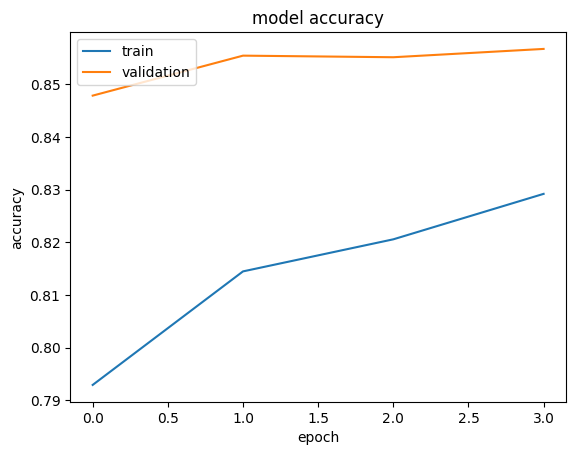

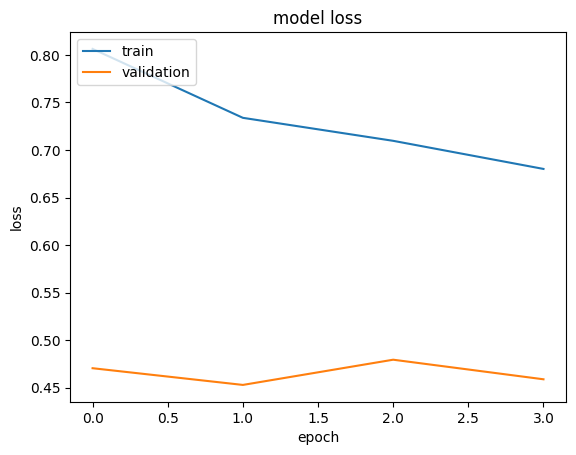

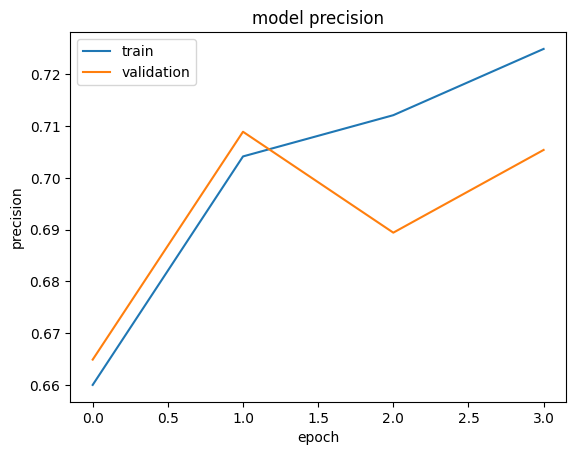

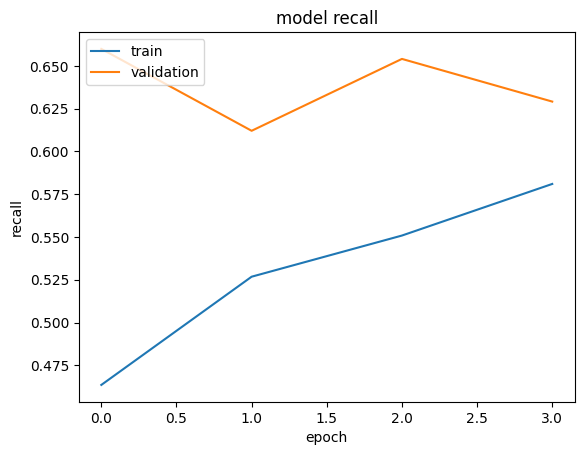

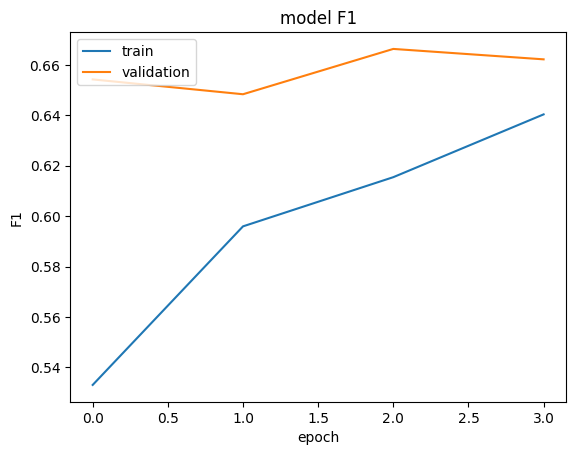

In [85]:
print(f'List of metrics: {history.history.keys()}')
for key in ['accuracy', 'loss', 'precision', 'recall', 'F1']:
    _ = plt.figure()
    plt.plot(history.history[key])
    plt.plot(history.history[f'val_{key}'])
    plt.title(f'model {key}')
    plt.ylabel(f'{key}')
    plt.xlabel('epoch')
    plt.legend(['train', 'validation'], loc='upper left')
    plt.show()
    wandb.log({str('plot_'+key):wandb.Image(_)})
    plt.close()

In [86]:
config.epochs = 5

In [87]:
%%time
for layer in basemodel.layers[397:]:  # starting block 6
    layer.trainable = True
optimizer = Adam(learning_rate=1e-4/2)
class_weights = [5, 1, 1]
model.compile(loss=weighted_binary_crossentropy(class_weights),
                      optimizer=optimizer,
                      metrics=METRICS
                     )


# to use with tf.data generator
history = model.fit(train_ds,
                    epochs = config.epochs,
                    steps_per_epoch = train_generator.samples // config.batch_size,
                    validation_data = valid_ds,
                    validation_steps = valid_generator.samples // config.batch_size,
                    # class_weight = weights,
                    callbacks = [
                        WandbMetricsLogger(),
                        # WandbModelCheckpoint(filepath='bestmodel.keras', save_best_only=True),
                        ModelCheckpoint(filepath='wandb/latest-run/files/best_model_6.keras', save_best_only=False),
                        ReduceLROnPlateau(monitor='auc_pneumothorax', factor=0.5, patience=2, verbose=1, min_delta=1e-4),
                        EarlyStopping(monitor='auc_pneumothorax', patience=3, verbose=1, min_delta=1e-4, restore_best_weights=True)]
                   )

Epoch 1/5


2025-05-12 15:42:11.588889: E tensorflow/core/grappler/optimizers/meta_optimizer.cc:961] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inmodel_1/block1b_drop/dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


15450/15450 [==============================] - 19265s 1s/step - loss: 0.8467 - accuracy: 0.8232 - precision: 0.7138 - recall: 0.5515 - auc: 0.8469 - F1: 0.6174 - auc_pneumothorax: 0.8511 - val_loss: 0.5665 - val_accuracy: 0.8571 - val_precision: 0.7067 - val_recall: 0.6295 - val_auc: 0.8603 - val_F1: 0.6627 - val_auc_pneumothorax: 0.8603 - lr: 5.0000e-05
Epoch 2/5
15450/15450 [==============================] - 19135s 1s/step - loss: 0.7861 - accuracy: 0.8315 - precision: 0.7298 - recall: 0.5859 - auc: 0.8623 - F1: 0.6474 - auc_pneumothorax: 0.8778 - val_loss: 0.5649 - val_accuracy: 0.8579 - val_precision: 0.6949 - val_recall: 0.6627 - val_auc: 0.8685 - val_F1: 0.6770 - val_auc_pneumothorax: 0.8760 - lr: 5.0000e-05
Epoch 3/5
15450/15450 [==============================] - ETA: 0s - loss: 0.7443 - accuracy: 0.8383 - precision: 0.7373 - recall: 0.6128 - auc: 0.8731 - F1: 0.6674 - auc_pneumothorax: 0.8976
Epoch 3: ReduceLROnPlateau reducing learning rate to 2.499999936844688e-05.
15450/1545

KeyboardInterrupt: 

In [90]:
config.epochs = 3
config.batch_size = 6

In [91]:
%%time
for layer in basemodel.layers[294:]:  # starting block 5
    layer.trainable = True
optimizer = Adam(learning_rate=1e-5)
class_weights = [5, 0.8, 0.8]
model.compile(loss=weighted_binary_crossentropy(class_weights),
                      optimizer=optimizer,
                      metrics=METRICS
                     )


# to use with tf.data generator
history = model.fit(train_ds,
                    epochs = config.epochs,
                    steps_per_epoch = train_generator.samples // config.batch_size,
                    validation_data = valid_ds,
                    validation_steps = valid_generator.samples // config.batch_size,
                    # class_weight = weights,
                    callbacks = [
                        WandbMetricsLogger(),
                        # WandbModelCheckpoint(filepath='bestmodel.keras', save_best_only=True),
                        ModelCheckpoint(filepath='wandb/latest-run/files/best_model_5.keras', save_best_only=False),
                        ReduceLROnPlateau(monitor='auc_pneumothorax', factor=0.5, patience=1, verbose=1, min_delta=1e-4),
                        EarlyStopping(monitor='auc_pneumothorax', patience=3, verbose=1, min_delta=1e-4, restore_best_weights=True)]
                   )

Epoch 1/3


2025-05-13 07:37:59.439257: E tensorflow/core/grappler/optimizers/meta_optimizer.cc:961] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inmodel_1/block1b_drop/dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


20600/20600 [==============================] - 24020s 1s/step - loss: 0.6439 - accuracy: 0.8452 - precision: 0.7453 - recall: 0.6376 - auc: 0.8824 - F1: 0.6859 - auc_pneumothorax: 0.9153 - val_loss: 0.5059 - val_accuracy: 0.8587 - val_precision: 0.6916 - val_recall: 0.6774 - val_auc: 0.8712 - val_F1: 0.6871 - val_auc_pneumothorax: 0.8753 - lr: 1.0000e-05
Epoch 2/3
20600/20600 [==============================] - ETA: 0s - loss: 0.6069 - accuracy: 0.8483 - precision: 0.7493 - recall: 0.6500 - auc: 0.8886 - F1: 0.6952 - auc_pneumothorax: 0.9304
Epoch 2: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-06.
20600/20600 [==============================] - 23982s 1s/step - loss: 0.6069 - accuracy: 0.8483 - precision: 0.7493 - recall: 0.6500 - auc: 0.8886 - F1: 0.6952 - auc_pneumothorax: 0.9304 - val_loss: 0.5032 - val_accuracy: 0.8591 - val_precision: 0.6848 - val_recall: 0.6982 - val_auc: 0.8716 - val_F1: 0.6939 - val_auc_pneumothorax: 0.8757 - lr: 1.0000e-05
Epoch 3/3
 6894/2060

KeyboardInterrupt: 

In [93]:
wandb.finish()

epoch/F1,▁▄▅▆▅▆▇██
epoch/accuracy,▁▄▄▆▅▆▇██
epoch/auc,▁▄▅▆▅▆▇██
epoch/auc_pneumothorax,▁▃▄▅▄▆▇▇█
epoch/epoch,▁▃▆█▁▃▆▁▃
epoch/learning_rate,███▄▂▂▂▁▁
epoch/loss,▇▅▄▃█▆▅▂▁
epoch/precision,▁▄▅▆▅▆▇██
epoch/recall,▁▃▄▅▄▆▇██
epoch/val_F1,▂▁▄▃▃▅▅▇█
epoch/val_accuracy,▁▆▆▇▇▇▇██


In [323]:
%%time
for layer in basemodel.layers[294:]:  # starting block 5
    layer.trainable = True
optimizer = Adam(learning_rate=1e-5)
class_weights = [6, 0.8, 0.8]
model.compile(loss=weighted_binary_crossentropy(class_weights),
                      optimizer=optimizer,
                      metrics=METRICS
                     )


# to use with tf.data generator
history = model.fit(train_ds,
                    epochs = config.epochs,
                    steps_per_epoch = train_generator.samples // config.batch_size,
                    validation_data = valid_ds,
                    validation_steps = valid_generator.samples // config.batch_size,
                    # class_weight = weights,
                    callbacks = [
                        WandbMetricsLogger(),
                        # WandbModelCheckpoint(filepath='bestmodel.keras', save_best_only=True),
                        ModelCheckpoint(filepath='wandb/latest-run/files/best_model_5_2.keras', save_best_only=False),
                        ReduceLROnPlateau(monitor='auc_pneumothorax', factor=0.5, patience=1, verbose=1, min_delta=1e-4),
                        EarlyStopping(monitor='auc_pneumothorax', patience=3, verbose=1, min_delta=1e-4, restore_best_weights=True)]
                   )

2025-05-01 21:56:02.196897: E tensorflow/core/grappler/optimizers/meta_optimizer.cc:961] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inmodel_1/block1b_drop/dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


89602/89602 [==============================] - 58174s 649ms/step - loss: 0.6705 - accuracy: 0.8603 - precision: 0.7592 - recall: 0.6554 - auc: 0.8964 - F1: 0.7022 - auc_pneumothorax: 0.9352 - val_loss: 0.5375 - val_accuracy: 0.8748 - val_precision: 0.7018 - val_recall: 0.7122 - val_auc: 0.9073 - val_F1: 0.7099 - val_auc_pneumothorax: 0.9188 - lr: 1.0000e-05
CPU times: user 10h 21min 2s, sys: 39min 20s, total: 11h 23s
Wall time: 16h 9min 34s


In [324]:
%%time
for layer in basemodel.layers[294:]:  # starting block 5
    layer.trainable = True
optimizer = Adam(learning_rate=1e-5)
class_weights = [6, 0.8, 0.8]
model.compile(loss=weighted_binary_crossentropy(class_weights),
                      optimizer=optimizer,
                      metrics=METRICS
                     )


# to use with tf.data generator
history = model.fit(train_ds,
                    epochs = config.epochs,
                    steps_per_epoch = train_generator.samples // config.batch_size,
                    validation_data = valid_ds,
                    validation_steps = valid_generator.samples // config.batch_size,
                    # class_weight = weights,
                    callbacks = [
                        WandbMetricsLogger(),
                        # WandbModelCheckpoint(filepath='bestmodel.keras', save_best_only=True),
                        ModelCheckpoint(filepath='wandb/latest-run/files/best_model_5_2.keras', save_best_only=False),
                        ReduceLROnPlateau(monitor='auc_pneumothorax', factor=0.5, patience=1, verbose=1, min_delta=1e-4),
                        EarlyStopping(monitor='auc_pneumothorax', patience=3, verbose=1, min_delta=1e-4, restore_best_weights=True)]
                   )

2025-05-02 14:05:37.060455: E tensorflow/core/grappler/optimizers/meta_optimizer.cc:961] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inmodel_1/block1b_drop/dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


89602/89602 [==============================] - 56778s 633ms/step - loss: 0.6564 - accuracy: 0.8638 - precision: 0.7631 - recall: 0.6671 - auc: 0.9006 - F1: 0.7104 - auc_pneumothorax: 0.9435 - val_loss: 0.5194 - val_accuracy: 0.8763 - val_precision: 0.6993 - val_recall: 0.7305 - val_auc: 0.9091 - val_F1: 0.7175 - val_auc_pneumothorax: 0.9220 - lr: 1.0000e-05
CPU times: user 10h 16min 58s, sys: 42min 41s, total: 10h 59min 40s
Wall time: 15h 46min 17s


In [327]:
%%time
for layer in basemodel.layers[294:]:  # starting block 5
    layer.trainable = True
optimizer = Adam(learning_rate=1e-5/4)
class_weights = [8, 0.8, 0.8]
model.compile(loss=weighted_binary_crossentropy(class_weights),
                      optimizer=optimizer,
                      metrics=METRICS
                     )


# to use with tf.data generator
history = model.fit(train_ds,
                    epochs = config.epochs,
                    steps_per_epoch = train_generator.samples // config.batch_size,
                    validation_data = valid_ds,
                    validation_steps = valid_generator.samples // config.batch_size,
                    # class_weight = weights,
                    callbacks = [
                        WandbMetricsLogger(),
                        # WandbModelCheckpoint(filepath='bestmodel.keras', save_best_only=True),
                        ModelCheckpoint(filepath='wandb/latest-run/files/best_model_5_3.keras', save_best_only=False),
                        ReduceLROnPlateau(monitor='auc_pneumothorax', factor=0.5, patience=1, verbose=1, min_delta=1e-4),
                        EarlyStopping(monitor='auc_pneumothorax', patience=3, verbose=1, min_delta=1e-4, restore_best_weights=True)]
                   )

2025-05-03 19:22:25.389454: E tensorflow/core/grappler/optimizers/meta_optimizer.cc:961] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inmodel_1/block1b_drop/dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


89602/89602 [==============================] - 55898s 624ms/step - loss: 0.7758 - accuracy: 0.8656 - precision: 0.7681 - recall: 0.6735 - auc: 0.9023 - F1: 0.7163 - auc_pneumothorax: 0.9468 - val_loss: 0.6517 - val_accuracy: 0.8751 - val_precision: 0.6947 - val_recall: 0.7332 - val_auc: 0.9084 - val_F1: 0.7172 - val_auc_pneumothorax: 0.9199 - lr: 2.5000e-06
CPU times: user 10h 13min 47s, sys: 46min 31s, total: 11h 18s
Wall time: 15h 31min 38s


In [329]:
%%time
for layer in basemodel.layers[294:]:  # starting block 5
    layer.trainable = True
optimizer = Adam(learning_rate=1e-5/4)
class_weights = [8, 0.8, 0.8]
model.compile(loss=weighted_binary_crossentropy(class_weights),
                      optimizer=optimizer,
                      metrics=METRICS
                     )


# to use with tf.data generator
history = model.fit(valid_ds,
                    epochs = config.epochs,
                    steps_per_epoch = valid_generator.samples // config.batch_size,
                    # validation_data = valid_ds,
                    # validation_steps = valid_generator.samples // config.batch_size,
                    # class_weight = weights,
                    callbacks = [
                        WandbMetricsLogger(),
                        # WandbModelCheckpoint(filepath='bestmodel.keras', save_best_only=True),
                        ModelCheckpoint(filepath='wandb/latest-run/files/best_model_5_valid_1.keras', save_best_only=False),
                        ReduceLROnPlateau(monitor='auc_pneumothorax', factor=0.5, patience=1, verbose=1, min_delta=1e-4),
                        EarlyStopping(monitor='auc_pneumothorax', patience=3, verbose=1, min_delta=1e-4, restore_best_weights=True)]
                   )

2025-05-04 13:03:02.971263: E tensorflow/core/grappler/optimizers/meta_optimizer.cc:961] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inmodel_1/block1b_drop/dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


6883/6883 [==============================] - 2366s 340ms/step - loss: 0.6628 - accuracy: 0.8479 - precision: 0.7146 - recall: 0.4710 - auc: 0.8306 - F1: 0.5681 - auc_pneumothorax: 0.8611 - lr: 2.5000e-06
CPU times: user 30min 1s, sys: 2min 14s, total: 32min 16s
Wall time: 39min 25s


In [330]:
%%time
for layer in basemodel.layers[294:]:  # starting block 5
    layer.trainable = True
optimizer = Adam(learning_rate=1e-5/4)
class_weights = [8, 0.8, 0.8]
model.compile(loss=weighted_binary_crossentropy(class_weights),
                      optimizer=optimizer,
                      metrics=METRICS
                     )


# to use with tf.data generator
history = model.fit(valid_ds,
                    epochs = config.epochs,
                    steps_per_epoch = valid_generator.samples // config.batch_size,
                    # validation_data = valid_ds,
                    # validation_steps = valid_generator.samples // config.batch_size,
                    # class_weight = weights,
                    callbacks = [
                        WandbMetricsLogger(),
                        # WandbModelCheckpoint(filepath='bestmodel.keras', save_best_only=True),
                        ModelCheckpoint(filepath='wandb/latest-run/files/best_model_5_valid_1.keras', save_best_only=False),
                        ReduceLROnPlateau(monitor='auc_pneumothorax', factor=0.5, patience=1, verbose=1, min_delta=1e-4),
                        EarlyStopping(monitor='auc_pneumothorax', patience=3, verbose=1, min_delta=1e-4, restore_best_weights=True)]
                   )

2025-05-04 14:21:52.564658: E tensorflow/core/grappler/optimizers/meta_optimizer.cc:961] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inmodel_1/block1b_drop/dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


6883/6883 [==============================] - 2424s 348ms/step - loss: 0.6378 - accuracy: 0.8445 - precision: 0.7192 - recall: 0.4378 - auc: 0.8209 - F1: 0.5446 - auc_pneumothorax: 0.8601 - lr: 2.5000e-06
CPU times: user 30min 12s, sys: 2min 15s, total: 32min 27s
Wall time: 40min 24s


Latest retraining using data from valid without proper preparation (very imbalanced) hurted the model. Let's just use good data with proper split

In [427]:
# Create generators for training using valid df (last step)
valid_train_1, _, _ = create_generators(df_train=valid_df_train1, x_col = 'filepath', y_col=targets, color_mode = config.color_mode,
                                                     augmentation = True, batch_size = config.batch_size, 
                                                     seed = 159, target_size = (config.image_size,config.image_size))
valid_train_2, _, _ = create_generators(df_train=valid_df_train2, x_col = 'filepath', y_col=targets, color_mode = config.color_mode,
                                                     augmentation = True, batch_size = config.batch_size, 
                                                     seed = 159, target_size = (config.image_size,config.image_size))

valid_train_1_ds = tf.data.Dataset.from_generator(lambda: valid_train_1,
                                        output_types=(tf.float32, tf.float32),
                                        output_shapes=([None, config.image_size,config.image_size,config.num_channels],
                                                      [None, num_classes]))
valid_train_2_ds = tf.data.Dataset.from_generator(lambda: valid_train_2,
                                        output_types=(tf.float32, tf.float32),
                                        output_shapes=([None, config.image_size,config.image_size,config.num_channels],
                                                      [None, num_classes]))
# train_ds = train_ds.prefetch(2)
# valid_ds = valid_ds.prefetch(2)

valid_train_1_ds = valid_train_1_ds.prefetch(tf.data.experimental.AUTOTUNE)
valid_train_2_ds = valid_train_2_ds.prefetch(tf.data.experimental.AUTOTUNE)

Found 5893 non-validated image filenames.
Found 27535 non-validated image filenames.
Found 27535 non-validated image filenames.
Found 63376 non-validated image filenames.
Found 27535 non-validated image filenames.
Found 27535 non-validated image filenames.


In [559]:
# This are the best general weights available (5_3 is worse because it started overfitting)
model.load_weights('wandb/latest-run/files/best_model_5_2.keras')

In [468]:
config.epochs = 3

In [470]:
%%time
for layer in basemodel.layers[294:]:  # starting block 5
    layer.trainable = True
optimizer = Adam(learning_rate=1e-5/2)
class_weights = [6, 0.8, 0.8]
model.compile(loss=weighted_binary_crossentropy(class_weights),
                      optimizer=optimizer,
                      metrics=METRICS
                     )


# to use with tf.data generator
history = model.fit(valid_train_1_ds,
                    epochs = config.epochs,
                    steps_per_epoch = valid_train_1.samples // config.batch_size,
                    # validation_data = valid_ds,
                    # validation_steps = valid_generator.samples // config.batch_size,
                    # class_weight = weights,
                    callbacks = [
                        WandbMetricsLogger(),
                        # WandbModelCheckpoint(filepath='bestmodel.keras', save_best_only=True),
# [checkpoint not released]                         ModelCheckpoint(filepath='wandb/latest-run/files/best_model_5_valid_2.keras', save_best_only=False),
                        ReduceLROnPlateau(monitor='auc_pneumothorax', factor=0.5, patience=1, verbose=1, min_delta=1e-4),
                        EarlyStopping(monitor='auc_pneumothorax', patience=3, verbose=1, min_delta=1e-4, restore_best_weights=True)]
                   )

Epoch 1/3


2025-05-05 02:48:52.864558: E tensorflow/core/grappler/optimizers/meta_optimizer.cc:961] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inmodel_1/block1b_drop/dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


1473/1473 [==============================] - 792s 519ms/step - loss: 0.8831 - accuracy: 0.8714 - precision: 0.7103 - recall: 0.7115 - auc: 0.9035 - F1: 0.7112 - auc_pneumothorax: 0.9128 - lr: 5.0000e-06
Epoch 2/3
1473/1473 [==============================] - 745s 506ms/step - loss: 0.8595 - accuracy: 0.8508 - precision: 0.7621 - recall: 0.6513 - auc: 0.8840 - F1: 0.7014 - auc_pneumothorax: 0.9062 - lr: 5.0000e-06
Epoch 3/3
1473/1473 [==============================] - ETA: 0s - loss: 0.8467 - accuracy: 0.8488 - precision: 0.7598 - recall: 0.6447 - auc: 0.8845 - F1: 0.6964 - auc_pneumothorax: 0.9088
Epoch 3: ReduceLROnPlateau reducing learning rate to 2.499999936844688e-06.
1473/1473 [==============================] - 737s 501ms/step - loss: 0.8467 - accuracy: 0.8488 - precision: 0.7598 - recall: 0.6447 - auc: 0.8845 - F1: 0.6964 - auc_pneumothorax: 0.9088 - lr: 5.0000e-06
CPU times: user 28min 17s, sys: 2min, total: 30min 18s
Wall time: 37min 54s


In [471]:
config.epochs = 1

In [472]:
%%time
for layer in basemodel.layers[294:]:  # starting block 5
    layer.trainable = True
optimizer = Adam(learning_rate=1e-5/3)
class_weights = [6, 0.8, 0.8]
model.compile(loss=weighted_binary_crossentropy(class_weights),
                      optimizer=optimizer,
                      metrics=METRICS
                     )


# to use with tf.data generator
history = model.fit(valid_train_2_ds,
                    epochs = config.epochs,
                    steps_per_epoch = valid_train_2.samples // config.batch_size,
                    # validation_data = valid_ds,
                    # validation_steps = valid_generator.samples // config.batch_size,
                    # class_weight = weights,
                    callbacks = [
                        WandbMetricsLogger(),
                        # WandbModelCheckpoint(filepath='bestmodel.keras', save_best_only=True),
                        ModelCheckpoint(filepath='wandb/latest-run/files/best_model_5_valid_3.keras', save_best_only=False),
                        ReduceLROnPlateau(monitor='auc_pneumothorax', factor=0.5, patience=1, verbose=1, min_delta=1e-4),
                        EarlyStopping(monitor='auc_pneumothorax', patience=3, verbose=1, min_delta=1e-4, restore_best_weights=True)]
                   )

Exception ignored in: <function tqdm.__del__ at 0x78eda1578160>
Traceback (most recent call last):
  File "/path/to/envs/dl/lib/python3.10/site-packages/tqdm/std.py", line 1162, in __del__
    
  File "/path/to/envs/dl/lib/python3.10/site-packages/tqdm/notebook.py", line 282, in close
    self.disp(bar_style='success', check_delay=False)
AttributeError: 'tqdm' object has no attribute 'disable'
2025-05-05 03:26:49.233083: E tensorflow/core/grappler/optimizers/meta_optimizer.cc:961] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inmodel_1/block1b_drop/dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


15844/15844 [==============================] - 9170s 577ms/step - loss: 1.3930 - accuracy: 0.8314 - precision: 0.8263 - recall: 0.6837 - auc: 0.8798 - F1: 0.7478 - auc_pneumothorax: 0.8991 - lr: 3.3333e-06
CPU times: user 1h 41min 2s, sys: 5min 37s, total: 1h 46min 40s
Wall time: 2h 32min 49s


In [71]:
from tensorflow.keras.models import load_model

In [72]:
model = load_model('wandb/latest-run/files/best_model.keras')

In [72]:
model.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_1 (InputLayer)        [(None, 456, 456, 3)]        0         []                            
                                                                                                  
 rescaling (Rescaling)       (None, 456, 456, 3)          0         ['input_1[0][0]']             
                                                                                                  
 normalization (Normalizati  (None, 456, 456, 3)          7         ['rescaling[0][0]']           
 on)                                                                                              
                                                                                                  
 rescaling_1 (Rescaling)     (None, 456, 456, 3)          0         ['normalization[0][0]']   

In [99]:
# 1. Set layer.trainable BEFORE compiling
# for layer in basemodel.layers:
#     layer.trainable = False
# 
# for layer in basemodel.layers[192:]:
#     layer.trainable = True

In [104]:
# class_weights = [1.5, 1, 0.8]
# model.compile(loss=weighted_binary_crossentropy(class_weights),
#                       optimizer=optimizer,
#                       metrics=METRICS
#                      )

In [101]:
from tensorflow.keras.models import load_model

In [102]:
# model = load_model('wandb/latest-run/files/best_model.keras')

2025-02-04 16:00:04.120219: W external/local_tsl/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 205520896 exceeds 10% of free system memory.


In [69]:
# config.num_classes = num_classes
# _, new_generator, _ = create_generators(df_train=train_df, df_test=valid_df.sample(200), x_col = 'filepath', y_col=targets, color_mode = config.color_mode,
#                                                      augmentation = True, batch_size = config.batch_size, 
#                                                      seed = 159, target_size = (config.image_size,config.image_size))

In [68]:
targets

['lateral']

In [93]:
test_generator = valid_generator

In [94]:
sample, label = next(test_generator)
for i in range(len(sample)):
    print(i, ">", label[i])
    plt.imshow(sample[i,:]/255)
    plt.show()

0 > [1. 1. 0.]


<Figure size 640x480 with 1 Axes>

1 > [0. 1. 0.]


<Figure size 640x480 with 1 Axes>

2 > [0. 1. 0.]


...

<Figure size 640x480 with 1 Axes>

6 > [0. 1. 0.]


<Figure size 640x480 with 1 Axes>

7 > [0. 0. 0.]


<Figure size 640x480 with 1 Axes>

In [95]:
# test_generator = valid_generator

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    precision_recall_curve, average_precision_score, roc_curve, auc
)
import pandas as pd

# ---------------------
# 1. Get Predictions
# ---------------------
# model: your keras model
# test_generator: your tf.keras.utils.Sequence or ImageDataGenerator (flow_from_dataframe)

# Get ground truth labels
y_true = test_generator.labels  # shape (samples, classes)
class_names = targets
n_classes = len(class_names)
print(f"CHECK {n_classes} TARGETS: {targets}")

# Get model probabilities
# y_probs = model.predict(test_generator, verbose=1)

CHECK 3 TARGETS: ['pneumothorax', 'support_devices', 'no_finding']


In [96]:
# Get model probabilities
y_probs = model.predict(test_generator, verbose=1)

# Get binary predictions
threshold = 0.5
y_pred = (y_probs >= threshold).astype(int)

print(f"Shapes: y_true {y_true.shape}, y_probs {y_probs.shape}, y_pred {y_pred.shape}")

3442/3442 [==============================] - 2372s 689ms/step
Shapes: y_true (27535, 3), y_probs (27535, 3), y_pred (27535, 3)


In [188]:
class_names

['pneumothorax', 'support_devices', 'no_finding']

In [97]:


# ---------------------
# 2. Global Metrics
# ---------------------
print("\n🌍 Global Metrics:")
metrics = {
    "accuracy": accuracy_score(y_true, y_pred),
    "macro_precision": precision_score(y_true, y_pred, average="macro"),
    "macro_recall": recall_score(y_true, y_pred, average="macro"),
    "macro_f1": f1_score(y_true, y_pred, average="macro"),
    "micro_precision": precision_score(y_true, y_pred, average="micro"),
    "micro_recall": recall_score(y_true, y_pred, average="micro"),
    "micro_f1": f1_score(y_true, y_pred, average="micro"),
    "weighted_precision": precision_score(y_true, y_pred, average="weighted"),
    "weighted_recall": recall_score(y_true, y_pred, average="weighted"),
    "weighted_f1": f1_score(y_true, y_pred, average="weighted"),
    "weighted_auc": roc_auc_score(y_true, y_probs, average="weighted"),
    
}
# wandb.log(metrics)
from pprint import pprint
pprint(metrics)

# ---------------------
# 3. Classification Report
# ---------------------
print("\n📋 Classification Report:")
if len(class_names) == 1:
    class_name = class_names[0]
    target_names = [f'{class_name}_negative', f'{class_name}_positive']
else:
    target_names = class_names
    
print(classification_report(y_true, y_pred, target_names=target_names, zero_division=0))
# Generate the classification report as a dictionary
report_dict = classification_report(y_true, y_pred, target_names=target_names, output_dict=True, zero_division=0)

# Convert to DataFrame
report_df = pd.DataFrame(report_dict).transpose()

# ---------------------
# 4. Per-Class Metrics and Plots
# ---------------------
per_class_metrics = []

for i, class_name in enumerate(class_names):

    # ROC Curve
    fpr, tpr, _ = roc_curve(y_true[:, i], y_probs[:, i])
    roc_auc = auc(fpr, tpr)
    fig_roc, ax = plt.subplots()
    ax.plot(fpr, tpr, label=f"AUC = {roc_auc:.2f}")
    ax.plot([0, 1], [0, 1], 'k--')
    ax.set_title(f"ROC Curve - {class_name}")
    ax.set_xlabel("FPR")
    ax.set_ylabel("TPR")
    ax.legend()
    wandb.log({f"ROC_{class_name}": wandb.Image(fig_roc)})
    plt.show()
    plt.close(fig_roc)

    # PR Curve
    precision, recall, _ = precision_recall_curve(y_true[:, i], y_probs[:, i])
    ap = average_precision_score(y_true[:, i], y_probs[:, i])
    # Remove first point if recall == 0 and precision == 1.0
    if recall[0] == 0 and precision[0] == 1.0:
        recall = recall[1:]
        precision = precision[1:]
    fig_pr, ax = plt.subplots()
    ax.plot(recall, precision, label=f"AP = {ap:.2f}")
    ax.set_title(f"Precision-Recall Curve - {class_name}")
    ax.set_xlabel("Recall")
    ax.set_ylabel("Precision")
    ax.legend()
    wandb.log({f"PR_{class_name}": wandb.Image(fig_pr)})
    plt.show()
    plt.close(fig_pr)

    # Confusion Matrix
    cm = confusion_matrix(y_true[:, i], y_pred[:, i], normalize='true')
    cm_raw = confusion_matrix(y_true[:, i], y_pred[:, i])
    fig_cm, ax = plt.subplots()
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax)
    ax.set_title(f"Confusion Matrix (row normalized) - {class_name}")
    wandb.log({f"Confusion_{class_name}": wandb.Image(fig_cm)})
    plt.show()
    plt.close(fig_cm)
    print(f'Confusion matrix without normalization')
    print(cm_raw)

    # Store per-class metrics
    per_class_metrics.append({
        "Class": class_name,
        "AUC": roc_auc,
        "Average Precision (AP)": ap,
        "Precision": precision_score(y_true[:, i], y_pred[:, i], zero_division=0),
        "Recall": recall_score(y_true[:, i], y_pred[:, i], zero_division=0),
        "F1": f1_score(y_true[:, i], y_pred[:, i], zero_division=0)
    })

# Optional: Display per-class metrics nicely
per_class_df = pd.DataFrame(per_class_metrics)
print("\n📈 Per-Class Metrics:")
print(per_class_df)

# ---------------------
# 5. Label Co-Occurrence
# ---------------------
print("\n🧩 Label Co-occurrence Analysis:")
co_occurrence = pd.DataFrame(y_true, columns=class_names).astype(int).T @ pd.DataFrame(y_true, columns=class_names).astype(int)
plt.figure(figsize=(8, 6))
sns.heatmap(co_occurrence, annot=True, fmt="d", cmap="Purples")
plt.title("Label Co-Occurrence Matrix")
wandb.log({f"Label Co-Occurrence Matrix": wandb.Image(fig_cm)})
plt.show()



🌍 Global Metrics:
{'accuracy': 0.656328309424369,
 'macro_f1': 0.6501210812205075,
 'macro_precision': 0.6169856262957546,
 'macro_recall': 0.7131059876476492,
 'micro_f1': 0.705174957548089,
 'micro_precision': 0.6881077850817624,
 'micro_recall': 0.7231102991550582,
 'weighted_auc': 0.9003342846585252,
 'weighted_f1': 0.7083284810170375,
 'weighted_precision': 0.7053249063547045,
 'weighted_recall': 0.7231102991550582}

📋 Classification Report:
                 precision    recall  f1-score   support

   pneumothorax       0.38      0.67      0.49      1393
support_devices       0.74      0.84      0.79      7473
     no_finding       0.72      0.63      0.67      8650

      micro avg       0.69      0.72      0.71     17516
      macro avg       0.62      0.71      0.65     17516
   weighted avg       0.71      0.72      0.71     17516
    samples avg       0.43      0.43      0.42     17516



<Figure size 640x480 with 1 Axes>

<Figure size 640x480 with 1 Axes>

<Figure size 640x480 with 2 Axes>

Confusion matrix without normalization
[[24643  1499]
 [  462   931]]


...

<Figure size 640x480 with 1 Axes>

<Figure size 640x480 with 1 Axes>

<Figure size 640x480 with 2 Axes>

Confusion matrix without normalization
[[16801  2084]
 [ 3194  5456]]

📈 Per-Class Metrics:
             Class       AUC  Average Precision (AP)  Precision    Recall        F1
0     pneumothorax  0.916705                0.527705   0.383128  0.668342  0.487052
1  support_devices  0.939157                0.825447   0.744222  0.840225  0.789315
2       no_finding  0.864158                0.747270   0.723607  0.630751  0.673996

🧩 Label Co-occurrence Analysis:


<Figure size 800x600 with 2 Axes>

In [98]:
report_df

,precision,recall,f1-score,support
pneumothorax,0.383128,0.668342,0.487052,1393.0
support_devices,0.744222,0.840225,0.789315,7473.0
no_finding,0.723607,0.630751,0.673996,8650.0
micro avg,0.688108,0.723110,0.705175,17516.0
macro avg,0.616986,0.713106,0.650121,17516.0
weighted avg,0.705325,0.723110,0.708328,17516.0
samples avg,0.426548,0.425404,0.421113,17516.0


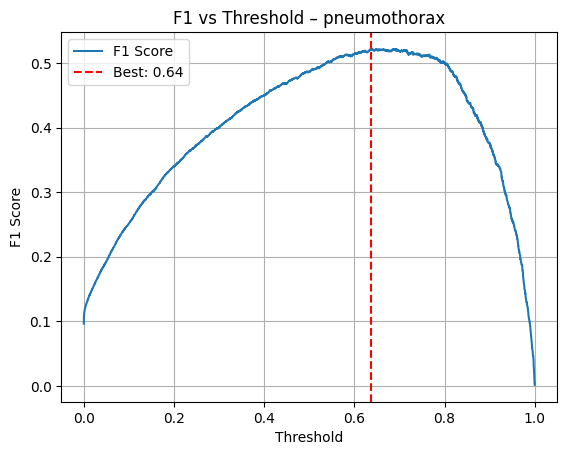

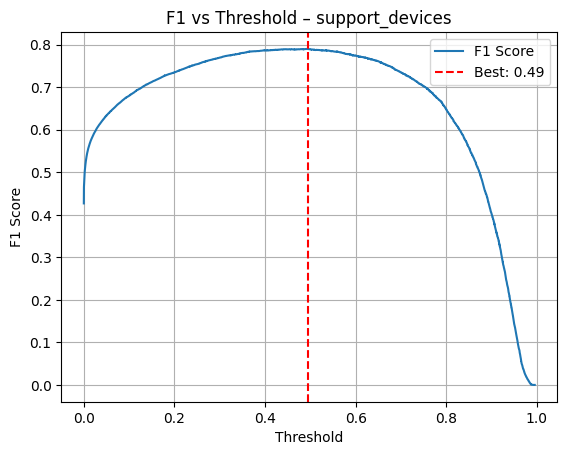

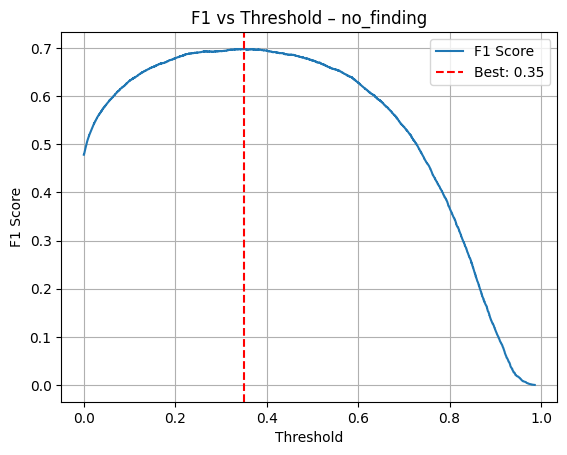

In [99]:
from sklearn.metrics import precision_recall_curve, f1_score
import wandb
import matplotlib.pyplot as plt

best_thresholds = {}
f1_scores = {}

for i, class_name in enumerate(class_names):
    true = y_true[:, i]
    probs = y_probs[:, i]

    precision, recall, thresholds = precision_recall_curve(true, probs)
    f1s = 2 * (precision * recall) / (precision + recall + 1e-8)

    best_idx = f1s.argmax()
    best_threshold = thresholds[best_idx]
    best_f1 = f1s[best_idx]

    best_thresholds[class_name] = best_threshold
    f1_scores[class_name] = best_f1

    # 🔁 Replot and log F1 vs threshold
    fig, ax = plt.subplots()
    ax.plot(thresholds, f1s[:-1], label="F1 Score")
    ax.axvline(best_threshold, color='r', linestyle='--', label=f"Best: {best_threshold:.2f}")
    ax.set_title(f"F1 vs Threshold – {class_name}")
    ax.set_xlabel("Threshold")
    ax.set_ylabel("F1 Score")
    ax.legend()
    ax.grid(True)
    wandb.log({f"F1_vs_Threshold_{class_name}": wandb.Image(fig)})
    plt.show()
    plt.close(fig)


In [100]:
threshold_table = wandb.Table(columns=["Class", "Best Threshold", "Best F1"])
for class_name in class_names:
    threshold_table.add_data(
        class_name,
        float(best_thresholds[class_name]),
        float(f1_scores[class_name])
    )
wandb.log({"Optimal Thresholds per Class": threshold_table})



📊 Final Metrics after Applying Best Thresholds:
{'accuracy': 0.6539313600871618,
 'macro_f1': 0.6699376896521638,
 'macro_precision': 0.6207659016645393,
 'macro_recall': 0.7278589914523123,
 'micro_f1': 0.7222837260793927,
 'micro_precision': 0.670894133777299,
 'micro_recall': 0.7821991322219685,
 'weighted_auc': 0.9003342846585252,
 'weighted_f1': 0.7231360288720357,
 'weighted_precision': 0.6725256125984899,
 'weighted_recall': 0.7821991322219685}

Classification Report:
                 precision    recall  f1-score   support

   pneumothorax       0.48      0.58      0.52      1393
support_devices       0.74      0.84      0.79      7473
     no_finding       0.64      0.76      0.70      8650

      micro avg       0.67      0.78      0.72     17516
      macro avg       0.62      0.73      0.67     17516
   weighted avg       0.67      0.78      0.72     17516
    samples avg       0.46      0.46      0.46     17516



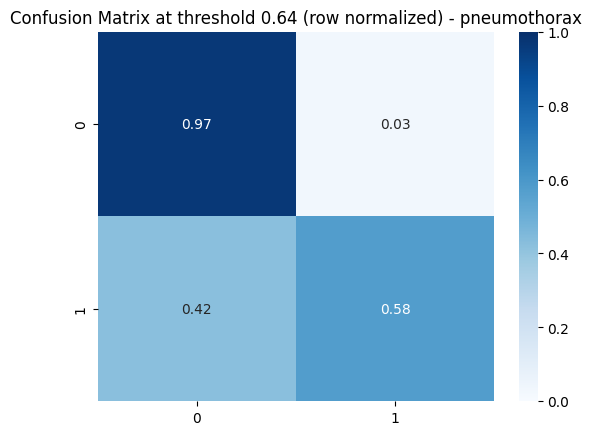

Confusion matrix without normalization - threshold 0.6360039114952087
[[25256   886]
 [  588   805]]


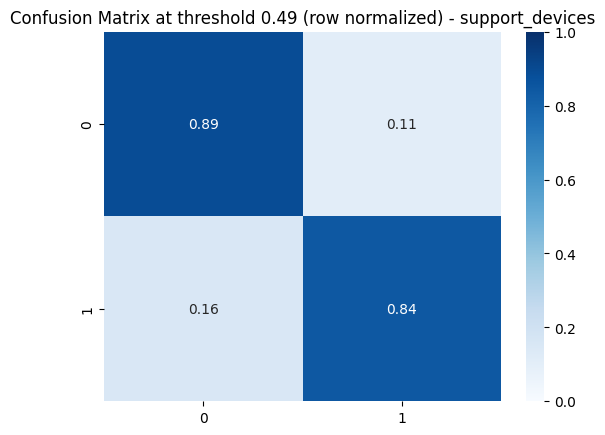

Confusion matrix without normalization - threshold 0.49471423029899597
[[17878  2184]
 [ 1167  6306]]


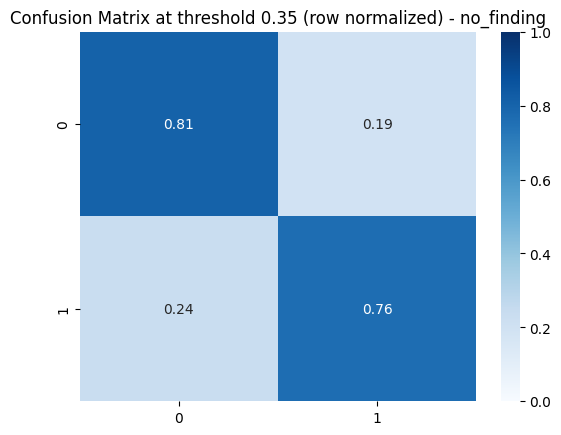

Confusion matrix without normalization - threshold 0.35139498114585876
[[15234  3651]
 [ 2060  6590]]

📈 Per-Class Metrics using threshold 0.35:
             Class  Precision    Recall        F1
0     pneumothorax   0.476050  0.577889  0.522049
1  support_devices   0.742756  0.843838  0.790077
2       no_finding   0.643492  0.761850  0.697687


In [101]:
# Create thresholded predictions using best thresholds per class
y_pred = np.zeros_like(y_probs)

for i, class_name in enumerate(class_names):
    threshold = best_thresholds[class_name]
    y_pred[:, i] = (y_probs[:, i] >= threshold).astype(int)

# New calculation using the final thresholds
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

# Use updated y_pred (from thresholded y_probs)
print("\n📊 Final Metrics after Applying Best Thresholds:")
best_threshold_metrics = {
    "accuracy": accuracy_score(y_true, y_pred),
    "macro_precision": precision_score(y_true, y_pred, average="macro"),
    "macro_recall": recall_score(y_true, y_pred, average="macro"),
    "macro_f1": f1_score(y_true, y_pred, average="macro"),
    "micro_precision": precision_score(y_true, y_pred, average="micro"),
    "micro_recall": recall_score(y_true, y_pred, average="micro"),
    "micro_f1": f1_score(y_true, y_pred, average="micro"),
    "weighted_precision": precision_score(y_true, y_pred, average="weighted"),
    "weighted_recall": recall_score(y_true, y_pred, average="weighted"),
    "weighted_f1": f1_score(y_true, y_pred, average="weighted"),
    "weighted_auc": roc_auc_score(y_true, y_probs, average="weighted"),
    
}
# wandb.log(metrics)
from pprint import pprint
pprint(best_threshold_metrics)

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=target_names, zero_division=0))
# Generate the classification report as a dictionary
report_dict_best_threshold = classification_report(y_true, y_pred, target_names=target_names, output_dict=True, zero_division=0)

# Convert to DataFrame
report_df_best_threshold = pd.DataFrame(report_dict_best_threshold).transpose()

per_class_metrics_threshold = []

for i, class_name in enumerate(class_names):
    threshold = best_thresholds[class_name]

    # Confusion Matrix optimized per threshold
    cm_threshold = confusion_matrix(y_true[:, i], y_pred[:, i], normalize='true')
    cm_raw_threshold = confusion_matrix(y_true[:, i], y_pred[:, i])
    fig_cm, ax = plt.subplots()
    sns.heatmap(cm_threshold, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax)
    ax.set_title(f"Confusion Matrix at threshold {threshold:.2f} (row normalized) - {class_name}")
    wandb.log({f"Confusion_{class_name}_threshold_{threshold}": wandb.Image(fig_cm)})
    plt.show()
    plt.close(fig_cm)
    print(f'Confusion matrix without normalization - threshold {threshold}')
    print(cm_raw_threshold)

    # Store per-class metrics
    per_class_metrics_threshold.append({
        "Class": class_name,
        # "AUC": roc_auc,
        # "Average Precision (AP)": ap,
        "Precision": precision_score(y_true[:, i], y_pred[:, i], zero_division=0),
        "Recall": recall_score(y_true[:, i], y_pred[:, i], zero_division=0),
        "F1": f1_score(y_true[:, i], y_pred[:, i], zero_division=0)
    })

# Optional: Display per-class metrics nicely
per_class_df_threshold = pd.DataFrame(per_class_metrics_threshold)
print(f"\n📈 Per-Class Metrics using threshold {threshold:.2f}:")
print(per_class_df_threshold)

In [102]:
report_df_best_threshold

,precision,recall,f1-score,support
pneumothorax,0.476050,0.577889,0.522049,1393.0
support_devices,0.742756,0.843838,0.790077,7473.0
no_finding,0.643492,0.761850,0.697687,8650.0
micro avg,0.670894,0.782199,0.722284,17516.0
macro avg,0.620766,0.727859,0.669938,17516.0
weighted avg,0.672526,0.782199,0.723136,17516.0
samples avg,0.464015,0.461794,0.458179,17516.0


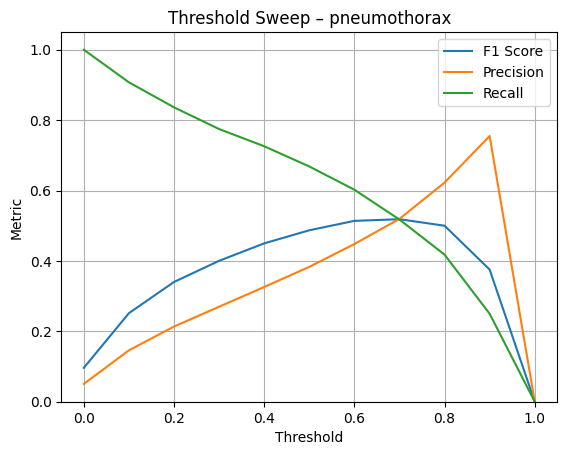

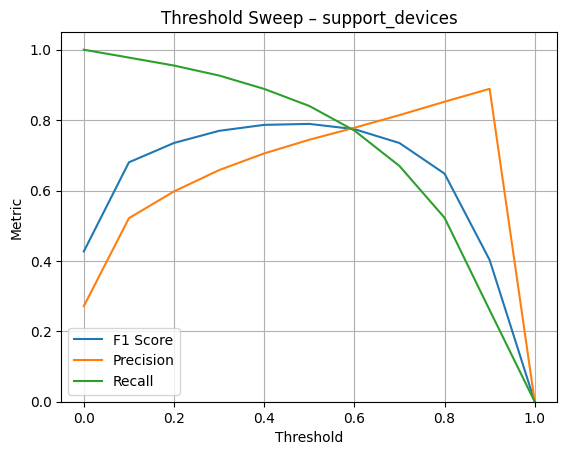

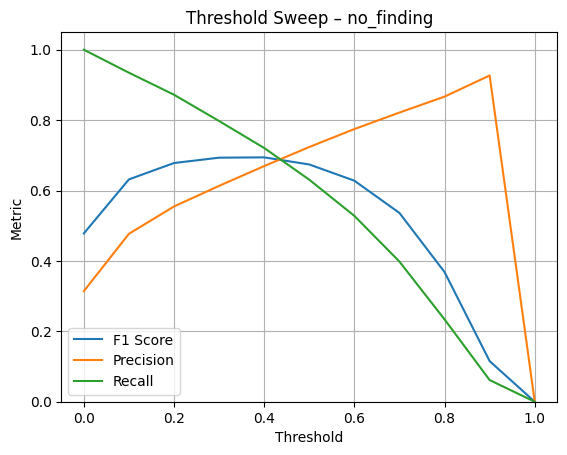

,Class,Threshold,Precision,Recall,F1 Score,TP,FP,FN,TN,total
0,pneumothorax,0.0,0.0506,1.0000,0.0963,1393,26142,0,0,27535
1,pneumothorax,0.1,0.1460,0.9074,0.2515,1264,7393,129,18749,27535
2,pneumothorax,0.2,0.2136,0.8363,0.3402,1165,4290,228,21852,27535
3,pneumothorax,0.3,0.2699,0.7746,0.4003,1079,2919,314,23223,27535
4,pneumothorax,0.4,0.3259,0.7258,0.4498,1011,2091,382,24051,27535
5,pneumothorax,0.5,0.3831,0.6683,0.4871,931,1499,462,24643,27535
6,pneumothorax,0.6,0.4479,0.6023,0.5138,839,1034,554,25108,27535
7,pneumothorax,0.7,0.5195,0.5176,0.5185,721,667,672,25475,27535
8,pneumothorax,0.8,0.6225,0.4178,0.5000,582,353,811,25789,27535
9,pneumothorax,0.9,0.7549,0.2498,0.3754,348,113,1045,26029,27535


In [103]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score, f1_score
import wandb

# Simulated input (replace with your own)
# y_true: shape (n_samples, n_classes)
# y_probs: predicted probabilities, same shape
# class_names: list of class names

thresholds = np.arange(0.0, 1.01, 0.1)
all_rows = []

# Loop through each class
for i, class_name in enumerate(class_names):
    true = y_true[:, i]
    probs = y_probs[:, i]

    # For overlay plot
    f1s, precisions, recalls = [], [], []

    for t in thresholds:
        preds = (probs >= t).astype(int)
        precision = precision_score(true, preds, zero_division=0)
        recall = recall_score(true, preds, zero_division=0)
        f1 = f1_score(true, preds, zero_division=0)
        tp = np.sum((true == 1) & (preds == 1))
        fp = np.sum((true == 0) & (preds == 1))
        fn = np.sum((true == 1) & (preds == 0))
        tn = int(np.sum((true == 0) & (preds == 0)))
        total_samples = tp + fp + fn + tn

        # Store metrics
        all_rows.append({
            "Class": class_name,
            "Threshold": round(t, 2),
            "Precision": round(precision, 4),
            "Recall": round(recall, 4),
            "F1 Score": round(f1, 4),
            "TP": int(tp),
            "FP": int(fp),
            "FN": int(fn),
            "TN": tn,
            "total": total_samples
        })

        f1s.append(f1)
        precisions.append(precision)
        recalls.append(recall)

    # Create overlay plot
    fig, ax = plt.subplots()
    ax.plot(thresholds, f1s, label="F1 Score")
    ax.plot(thresholds, precisions, label="Precision")
    ax.plot(thresholds, recalls, label="Recall")
    ax.set_title(f"Threshold Sweep – {class_name}")
    ax.set_xlabel("Threshold")
    ax.set_ylabel("Metric")
    ax.set_ylim(0, 1.05)
    ax.legend()
    ax.grid(True)
    wandb.log({f"Threshold Metrics - {class_name}": wandb.Image(fig)})
    plt.show()
    plt.close(fig)

# Log table to WandB
threshold_df = pd.DataFrame(all_rows)
table = wandb.Table(dataframe=threshold_df)
wandb.log({"Threshold Table (All Classes)": table})
threshold_df


In [104]:
i = 0
true = y_true[:, i]
probs = y_probs[:, i]

In [105]:
i = 0
true = y_true[:, i]
probs = y_probs[:, i]

desired_precision = np.arange(0.4,0.85,0.05)
desired_recall = np.arange(0.75,1,0.05)

for desired_prec in desired_precision:
    best_recall = 0
    best_threshold = 0
    precision, recall, thresholds = precision_recall_curve(true, probs)
    for thr, prec, rec in zip(thresholds, precision, recall):
        if prec >= desired_prec:  # minimum acceptable precision
            if rec > best_recall:
                best_recall = rec
                best_threshold = thr

    print(f"✅ Best threshold = {best_threshold:.2f} with Recall = {best_recall:.3f} and Precision >= {desired_prec:.2f}")


✅ Best threshold = 0.53 with Recall = 0.650 and Precision >= 0.40
✅ Best threshold = 0.60 with Recall = 0.602 and Precision >= 0.45
✅ Best threshold = 0.68 with Recall = 0.539 and Precision >= 0.50
✅ Best threshold = 0.73 with Recall = 0.484 and Precision >= 0.55
✅ Best threshold = 0.78 with Recall = 0.441 and Precision >= 0.60
✅ Best threshold = 0.83 with Recall = 0.380 and Precision >= 0.65
✅ Best threshold = 0.87 with Recall = 0.293 and Precision >= 0.70
✅ Best threshold = 0.90 with Recall = 0.252 and Precision >= 0.75
✅ Best threshold = 0.94 with Recall = 0.181 and Precision >= 0.80


In [106]:
desired_recall = np.arange(0.75,1,0.05)

for desired_recall in desired_recall:
    best_precision = 0
    best_threshold = 0
    precision, recall, thresholds = precision_recall_curve(true, probs)
    for thr, prec, rec in zip(thresholds, precision, recall):
        if rec >= desired_recall:  # minimum acceptable precision
            if prec > best_precision:
                best_precision = prec
                best_threshold = thr

    print(f"✅ Best threshold = {best_threshold:.2f} with Precision = {best_precision:.3f} and Recall >= {desired_recall:.2f}")


✅ Best threshold = 0.35 with Precision = 0.302 and Recall >= 0.75
✅ Best threshold = 0.26 with Precision = 0.249 and Recall >= 0.80
✅ Best threshold = 0.18 with Precision = 0.199 and Recall >= 0.85
✅ Best threshold = 0.11 with Precision = 0.152 and Recall >= 0.90
✅ Best threshold = 0.05 with Precision = 0.111 and Recall >= 0.95


In [119]:
manual_thresolds = best_thresholds.copy()
manual_thresolds['pneumothorax'] = 0.20

In [120]:
manual_thresolds

{'pneumothorax': 0.2, 'support_devices': 0.49471423, 'no_finding': 0.35139498}

In [121]:
# Create thresholded predictions using best thresholds per class
y_pred = np.zeros_like(y_probs)

for i, class_name in enumerate(class_names):
    threshold = manual_thresolds[class_name]
    y_pred[:, i] = (y_probs[:, i] >= threshold).astype(int)



📊 Final Metrics after Applying Best Thresholds:
{'accuracy': 0.5828944979117486,
 'macro_f1': 0.6093363698061897,
 'macro_precision': 0.5332711888167548,
 'macro_recall': 0.8140040022204387,
 'micro_f1': 0.674356145988202,
 'micro_precision': 0.5813693872488216,
 'micro_recall': 0.802751769810459,
 'weighted_auc': 0.9003342846585252,
 'weighted_f1': 0.7086776527795302,
 'weighted_precision': 0.6516509605665823,
 'weighted_recall': 0.802751769810459}

Classification Report:
                 precision    recall  f1-score   support

   pneumothorax       0.21      0.84      0.34      1393
support_devices       0.74      0.84      0.79      7473
     no_finding       0.64      0.76      0.70      8650

      micro avg       0.58      0.80      0.67     17516
      macro avg       0.53      0.81      0.61     17516
   weighted avg       0.65      0.80      0.71     17516
    samples avg       0.44      0.47      0.45     17516



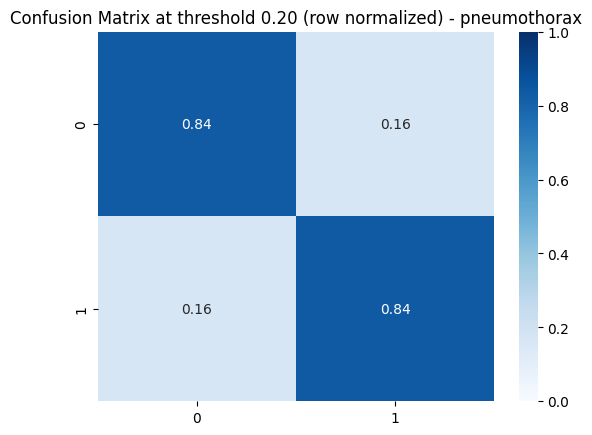

Confusion matrix without normalization - threshold 0.2
[[21852  4290]
 [  228  1165]]


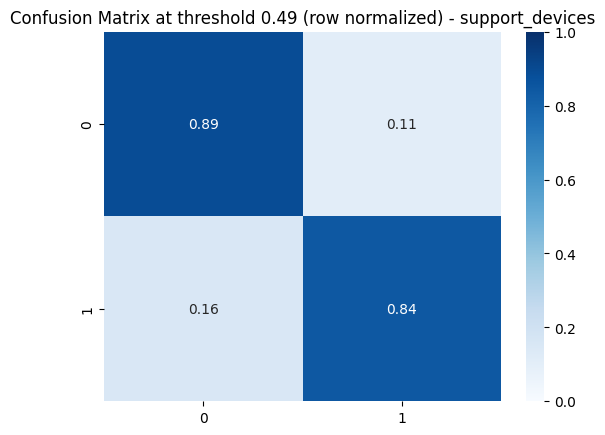

Confusion matrix without normalization - threshold 0.49471423029899597
[[17878  2184]
 [ 1167  6306]]


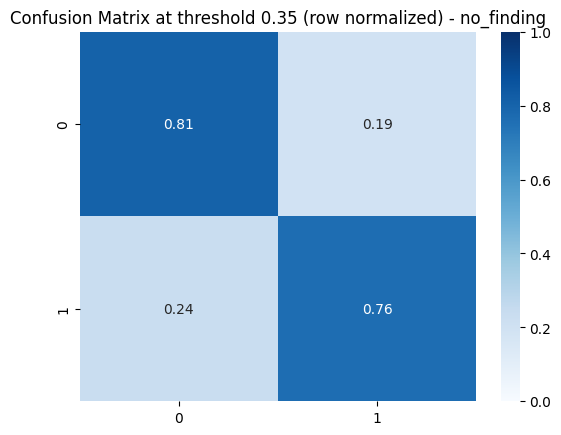

Confusion matrix without normalization - threshold 0.35139498114585876
[[15234  3651]
 [ 2060  6590]]

📈 Per-Class Metrics using threshold 0.35:
             Class       AUC  Average Precision (AP)  Precision    Recall        F1
0     pneumothorax  0.864158                 0.74727   0.213566  0.836324  0.340245
1  support_devices  0.864158                 0.74727   0.742756  0.843838  0.790077
2       no_finding  0.864158                 0.74727   0.643492  0.761850  0.697687


In [122]:
# New calculation using the final thresholds
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

# Use updated y_pred (from thresholded y_probs)
print("\n📊 Final Metrics after Applying Best Thresholds:")
best_threshold_metrics = {
    "accuracy": accuracy_score(y_true, y_pred),
    "macro_precision": precision_score(y_true, y_pred, average="macro"),
    "macro_recall": recall_score(y_true, y_pred, average="macro"),
    "macro_f1": f1_score(y_true, y_pred, average="macro"),
    "micro_precision": precision_score(y_true, y_pred, average="micro"),
    "micro_recall": recall_score(y_true, y_pred, average="micro"),
    "micro_f1": f1_score(y_true, y_pred, average="micro"),
    "weighted_precision": precision_score(y_true, y_pred, average="weighted"),
    "weighted_recall": recall_score(y_true, y_pred, average="weighted"),
    "weighted_f1": f1_score(y_true, y_pred, average="weighted"),
    "weighted_auc": roc_auc_score(y_true, y_probs, average="weighted"),
    
}
# wandb.log(metrics)
from pprint import pprint
pprint(best_threshold_metrics)

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=target_names, zero_division=0))
# Generate the classification report as a dictionary
report_dict_best_threshold = classification_report(y_true, y_pred, target_names=target_names, output_dict=True, zero_division=0)

# Convert to DataFrame
report_df_best_threshold = pd.DataFrame(report_dict_best_threshold).transpose()

per_class_metrics_threshold = []

for i, class_name in enumerate(class_names):
    threshold = manual_thresolds[class_name]

    # Confusion Matrix optimized per threshold
    cm_threshold = confusion_matrix(y_true[:, i], y_pred[:, i], normalize='true')
    cm_raw_threshold = confusion_matrix(y_true[:, i], y_pred[:, i])
    fig_cm, ax = plt.subplots()
    sns.heatmap(cm_threshold, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax)
    ax.set_title(f"Confusion Matrix at threshold {threshold:.2f} (row normalized) - {class_name}")
    wandb.log({f"Confusion_{class_name}_threshold_{threshold}": wandb.Image(fig_cm)})
    plt.show()
    plt.close(fig_cm)
    print(f'Confusion matrix without normalization - threshold {threshold}')
    print(cm_raw_threshold)

    # Store per-class metrics
    per_class_metrics_threshold.append({
        "Class": class_name,
        "AUC": roc_auc,
        "Average Precision (AP)": ap,
        "Precision": precision_score(y_true[:, i], y_pred[:, i], zero_division=0),
        "Recall": recall_score(y_true[:, i], y_pred[:, i], zero_division=0),
        "F1": f1_score(y_true[:, i], y_pred[:, i], zero_division=0)
    })

# Optional: Display per-class metrics nicely
per_class_df_threshold = pd.DataFrame(per_class_metrics_threshold)
print(f"\n📈 Per-Class Metrics using threshold {threshold:.2f}:")
print(per_class_df_threshold)

In [123]:
import matplotlib.pyplot as plt
import numpy as np

def get_model_errors(y_true, y_probs, image_paths, class_names, threshold=0.5, top_k=10, images_per_row=5, show_errors=True):
    y_pred = (y_probs >= threshold).astype(int)
    errors = {}

    for i, class_name in enumerate(class_names):
        fp_idx = np.where((y_pred[:, i] == 1) & (y_true[:, i] == 0))[0]
        fn_idx = np.where((y_pred[:, i] == 0) & (y_true[:, i] == 1))[0]

        errors[class_name] = {
            "false_positives": [(image_paths[idx], y_probs[idx, i]) for idx in fp_idx],
            "false_negatives": [(image_paths[idx], y_probs[idx, i]) for idx in fn_idx],
        }

        if show_errors:
            print(f"\n🧪 Class: {class_name}")
            print(f"  ❌ False Positives: {len(fp_idx)} | ❌ False Negatives: {len(fn_idx)}")

            def show_imgs(indices, title):
                n = min(len(indices), top_k)
                rows = (n + images_per_row - 1) // images_per_row
                fig, axes = plt.subplots(rows, images_per_row, figsize=(images_per_row * 3, rows * 3))

                if rows == 1:
                    axes = np.expand_dims(axes, 0)  # make sure it's 2D
                axes = axes.flatten()

                for j in range(n):
                    idx = indices[j]
                    img = plt.imread(image_paths[idx])
                    axes[j].imshow(img, cmap='gray')
                    axes[j].set_title(f"{title}\nConf: {y_probs[idx, i]:.2f}")
                    axes[j].axis("off")

                for ax in axes[n:]:
                    ax.axis("off")

                plt.tight_layout()
                plt.show()

            if len(fp_idx) > 0:
                print("🔺 False Positives:")
                show_imgs(fp_idx, "FP")
            if len(fn_idx) > 0:
                print("🔻 False Negatives:")
                show_imgs(fn_idx, "FN")

    return errors


In [124]:
image_paths = test_generator.filepaths  # From ImageDataGenerator

errors = get_model_errors(
    y_true=y_true,
    y_probs=y_probs,
    image_paths=image_paths,
    class_names=class_names,
    threshold=0.5,
    top_k=13
)



🧪 Class: pneumothorax
  ❌ False Positives: 1499 | ❌ False Negatives: 462
🔺 False Positives:


<Figure size 1500x900 with 15 Axes>

🔻 False Negatives:


<Figure size 1500x900 with 15 Axes>


🧪 Class: support_devices
  ❌ False Positives: 2158 | ❌ False Negatives: 1194
🔺 False Positives:


...

<Figure size 1500x900 with 15 Axes>


🧪 Class: no_finding
  ❌ False Positives: 2084 | ❌ False Negatives: 3194
🔺 False Positives:


<Figure size 1500x900 with 15 Axes>

🔻 False Negatives:


<Figure size 1500x900 with 15 Axes>

In [251]:
# Last retraining

528/528 [==============================] - 27s 47ms/step
Shapes: y_true (2110, 3), y_probs (2110, 3), y_pred (2110, 3)

🌍 Global Metrics:
{'accuracy': 0.6312796208530805,
 'macro_f1': 0.6627439517041793,
 'macro_precision': 0.6555724560370998,
 'macro_recall': 0.6783205965884928,
 'micro_f1': 0.7122112211221122,
 'micro_precision': 0.7033898305084746,
 'micro_recall': 0.7212566844919787,
 'weighted_auc': 0.8663553220336067,
 'weighted_f1': 0.7093494934731674,
 'weighted_precision': 0.7042056941015172,
 'weighted_recall': 0.7212566844919787}

📋 Classification Report:
                 precision    recall  f1-score   support

   pneumothorax       0.68      0.86      0.76       422
support_devices       0.55      0.48      0.51       135
     no_finding       0.74      0.69      0.71       939

      micro avg       0.70      0.72      0.71      1496
      macro avg       0.66      0.68      0.66      1496
   weighted avg       0.70      0.72      0.71      1496
    samples avg       0.47

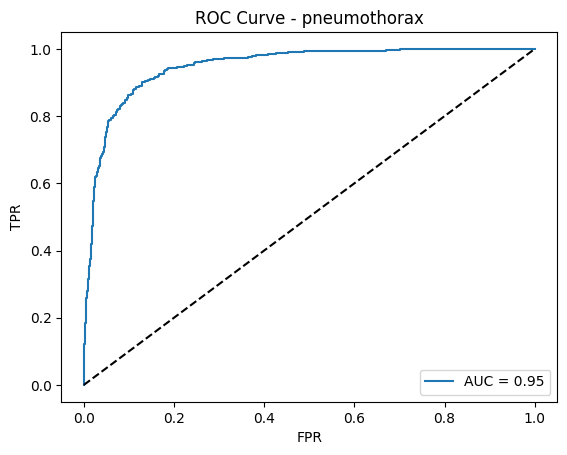

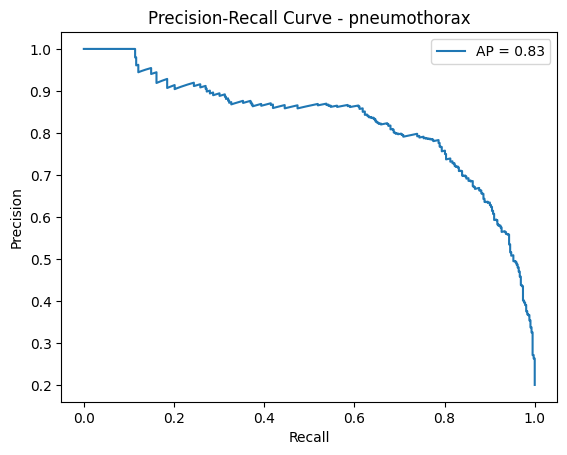

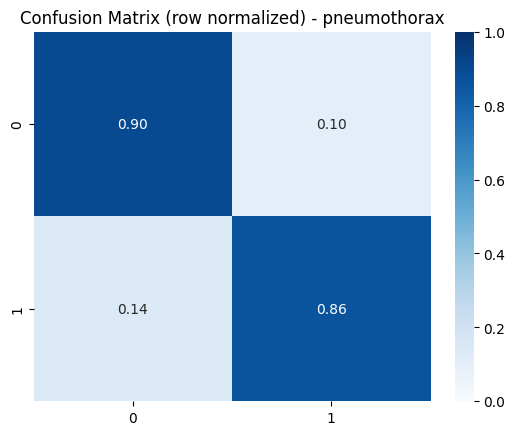

Confusion matrix without normalization
[[1521  167]
 [  59  363]]


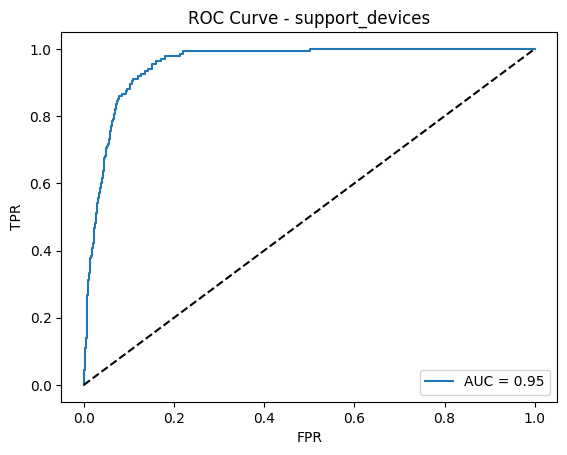

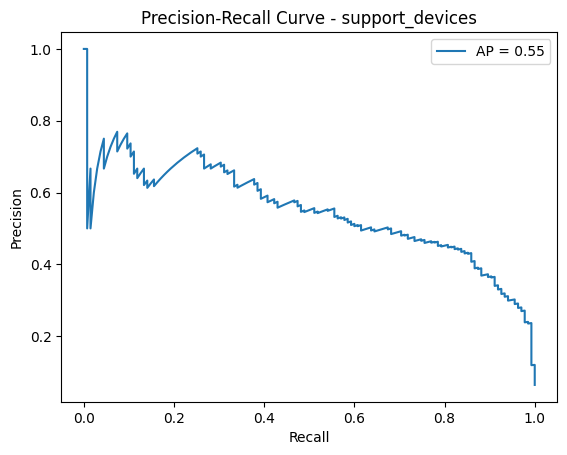

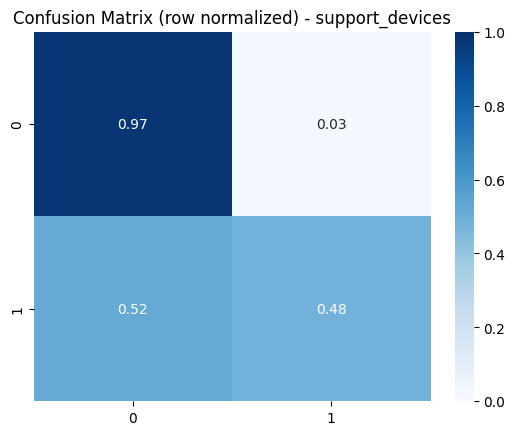

Confusion matrix without normalization
[[1921   54]
 [  70   65]]


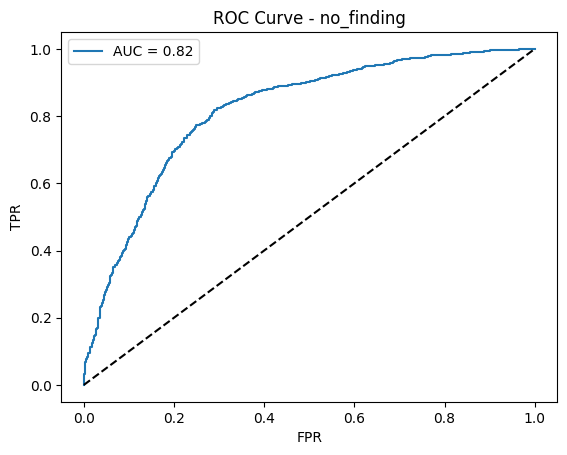

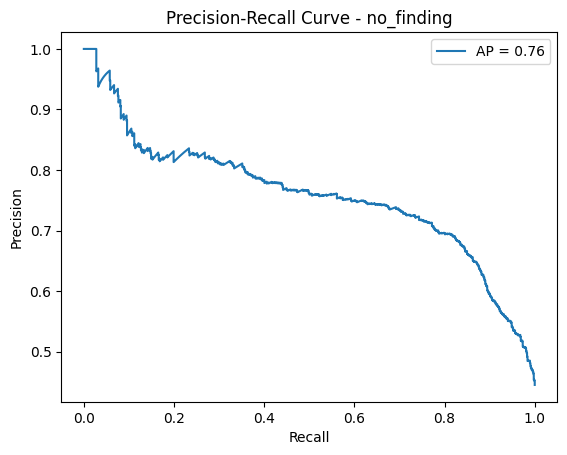

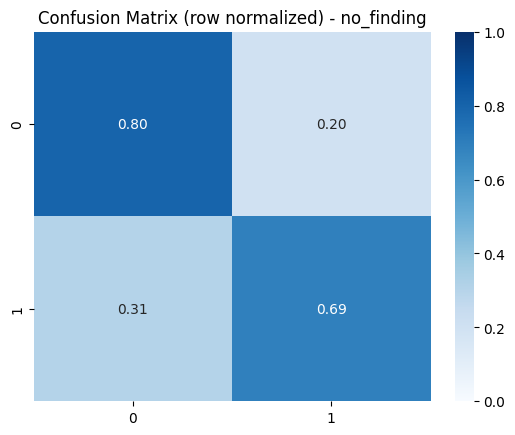

Confusion matrix without normalization
[[937 234]
 [288 651]]

📈 Per-Class Metrics:
             Class       AUC  Average Precision (AP)  Precision    Recall        F1
0     pneumothorax  0.948568                0.825965   0.684906  0.860190  0.762605
1  support_devices  0.954948                0.551122   0.546218  0.481481  0.511811
2       no_finding  0.816671                0.758884   0.735593  0.693291  0.713816


,precision,recall,f1-score,support
pneumothorax,0.684906,0.860190,0.762605,422.0
support_devices,0.546218,0.481481,0.511811,135.0
no_finding,0.735593,0.693291,0.713816,939.0
micro avg,0.703390,0.721257,0.712211,1496.0
macro avg,0.655572,0.678321,0.662744,1496.0
weighted avg,0.704206,0.721257,0.709349,1496.0
samples avg,0.471327,0.468246,0.465877,1496.0


In [252]:
# Get model probabilities
y_probs = model.predict(test_generator, verbose=1)

# Get binary predictions
threshold = 0.5
y_pred = (y_probs >= threshold).astype(int)

print(f"Shapes: y_true {y_true.shape}, y_probs {y_probs.shape}, y_pred {y_pred.shape}")

# ---------------------
# 2. Global Metrics
# ---------------------
print("\n🌍 Global Metrics:")
metrics = {
    "accuracy": accuracy_score(y_true, y_pred),
    "macro_precision": precision_score(y_true, y_pred, average="macro"),
    "macro_recall": recall_score(y_true, y_pred, average="macro"),
    "macro_f1": f1_score(y_true, y_pred, average="macro"),
    "micro_precision": precision_score(y_true, y_pred, average="micro"),
    "micro_recall": recall_score(y_true, y_pred, average="micro"),
    "micro_f1": f1_score(y_true, y_pred, average="micro"),
    "weighted_precision": precision_score(y_true, y_pred, average="weighted"),
    "weighted_recall": recall_score(y_true, y_pred, average="weighted"),
    "weighted_f1": f1_score(y_true, y_pred, average="weighted"),
    "weighted_auc": roc_auc_score(y_true, y_probs, average="weighted"),
    
}
# wandb.log(metrics)
from pprint import pprint
pprint(metrics)

# ---------------------
# 3. Classification Report
# ---------------------
print("\n📋 Classification Report:")
if len(class_names) == 1:
    class_name = class_names[0]
    target_names = [f'{class_name}_negative', f'{class_name}_positive']
else:
    target_names = class_names
    
print(classification_report(y_true, y_pred, target_names=target_names, zero_division=0))
# Generate the classification report as a dictionary
report_dict = classification_report(y_true, y_pred, target_names=target_names, output_dict=True, zero_division=0)

# Convert to DataFrame
report_df = pd.DataFrame(report_dict).transpose()

# ---------------------
# 4. Per-Class Metrics and Plots
# ---------------------
per_class_metrics = []

for i, class_name in enumerate(class_names):

    # ROC Curve
    fpr, tpr, _ = roc_curve(y_true[:, i], y_probs[:, i])
    roc_auc = auc(fpr, tpr)
    fig_roc, ax = plt.subplots()
    ax.plot(fpr, tpr, label=f"AUC = {roc_auc:.2f}")
    ax.plot([0, 1], [0, 1], 'k--')
    ax.set_title(f"ROC Curve - {class_name}")
    ax.set_xlabel("FPR")
    ax.set_ylabel("TPR")
    ax.legend()
    wandb.log({f"ROC_{class_name}": wandb.Image(fig_roc)})
    plt.show()
    plt.close(fig_roc)

    # PR Curve
    precision, recall, _ = precision_recall_curve(y_true[:, i], y_probs[:, i])
    ap = average_precision_score(y_true[:, i], y_probs[:, i])
    # Remove first point if recall == 0 and precision == 1.0
    if recall[0] == 0 and precision[0] == 1.0:
        recall = recall[1:]
        precision = precision[1:]
    fig_pr, ax = plt.subplots()
    ax.plot(recall, precision, label=f"AP = {ap:.2f}")
    ax.set_title(f"Precision-Recall Curve - {class_name}")
    ax.set_xlabel("Recall")
    ax.set_ylabel("Precision")
    ax.legend()
    wandb.log({f"PR_{class_name}": wandb.Image(fig_pr)})
    plt.show()
    plt.close(fig_pr)

    # Confusion Matrix
    cm = confusion_matrix(y_true[:, i], y_pred[:, i], normalize='true')
    cm_raw = confusion_matrix(y_true[:, i], y_pred[:, i])
    fig_cm, ax = plt.subplots()
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax)
    ax.set_title(f"Confusion Matrix (row normalized) - {class_name}")
    wandb.log({f"Confusion_{class_name}": wandb.Image(fig_cm)})
    plt.show()
    plt.close(fig_cm)
    print(f'Confusion matrix without normalization')
    print(cm_raw)

    # Store per-class metrics
    per_class_metrics.append({
        "Class": class_name,
        "AUC": roc_auc,
        "Average Precision (AP)": ap,
        "Precision": precision_score(y_true[:, i], y_pred[:, i], zero_division=0),
        "Recall": recall_score(y_true[:, i], y_pred[:, i], zero_division=0),
        "F1": f1_score(y_true[:, i], y_pred[:, i], zero_division=0)
    })

# Optional: Display per-class metrics nicely
per_class_df = pd.DataFrame(per_class_metrics)
print("\n📈 Per-Class Metrics:")
print(per_class_df)

report_df

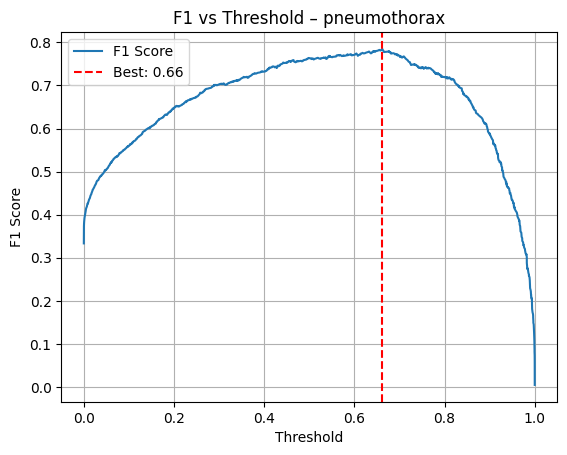

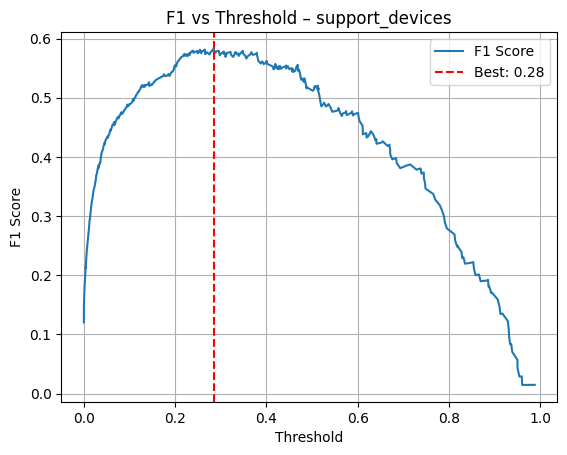

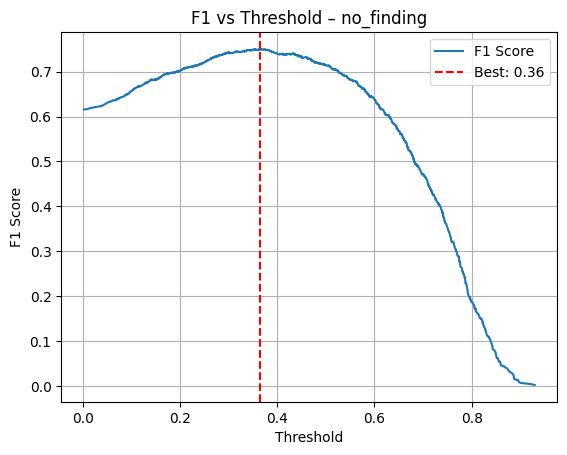

In [253]:
from sklearn.metrics import precision_recall_curve, f1_score
import wandb
import matplotlib.pyplot as plt

best_thresholds = {}
f1_scores = {}

for i, class_name in enumerate(class_names):
    true = y_true[:, i]
    probs = y_probs[:, i]

    precision, recall, thresholds = precision_recall_curve(true, probs)
    f1s = 2 * (precision * recall) / (precision + recall + 1e-8)

    best_idx = f1s.argmax()
    best_threshold = thresholds[best_idx]
    best_f1 = f1s[best_idx]

    best_thresholds[class_name] = best_threshold
    f1_scores[class_name] = best_f1

    # 🔁 Replot and log F1 vs threshold
    fig, ax = plt.subplots()
    ax.plot(thresholds, f1s[:-1], label="F1 Score")
    ax.axvline(best_threshold, color='r', linestyle='--', label=f"Best: {best_threshold:.2f}")
    ax.set_title(f"F1 vs Threshold – {class_name}")
    ax.set_xlabel("Threshold")
    ax.set_ylabel("F1 Score")
    ax.legend()
    ax.grid(True)
    wandb.log({f"F1_vs_Threshold_{class_name}": wandb.Image(fig)})
    plt.show()
    plt.close(fig)



📊 Final Metrics after Applying Best Thresholds:
{'accuracy': 0.6464454976303318,
 'macro_f1': 0.7060458286420074,
 'macro_precision': 0.6453598451409897,
 'macro_recall': 0.7983770768128434,
 'micro_f1': 0.7408993576017131,
 'micro_precision': 0.6830231246474902,
 'micro_recall': 0.8094919786096256,
 'weighted_auc': 0.8663553220336067,
 'weighted_f1': 0.7452470489592383,
 'weighted_precision': 0.6958560988001415,
 'weighted_recall': 0.8094919786096256}

Classification Report:
                 precision    recall  f1-score   support

   pneumothorax       0.78      0.79      0.78       422
support_devices       0.46      0.79      0.58       135
     no_finding       0.69      0.82      0.75       939

      micro avg       0.68      0.81      0.74      1496
      macro avg       0.65      0.80      0.71      1496
   weighted avg       0.70      0.81      0.75      1496
    samples avg       0.51      0.52      0.51      1496



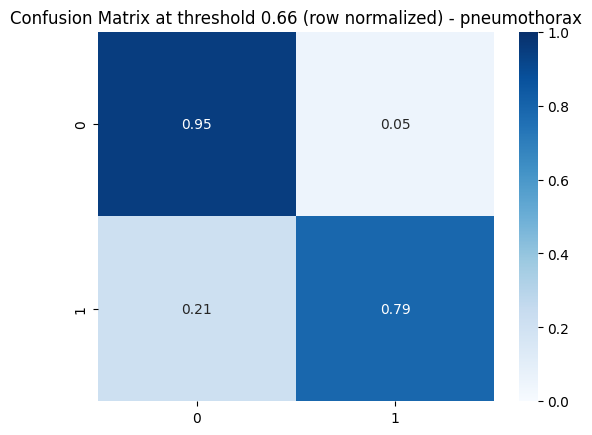

Confusion matrix without normalization - threshold 0.6618962287902832
[[1596   92]
 [  90  332]]


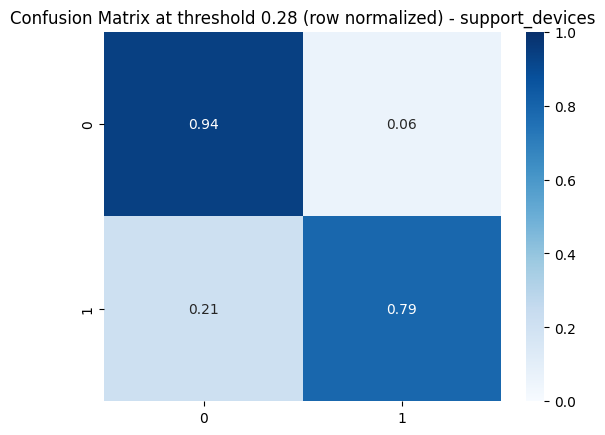

Confusion matrix without normalization - threshold 0.2840953469276428
[[1852  123]
 [  29  106]]


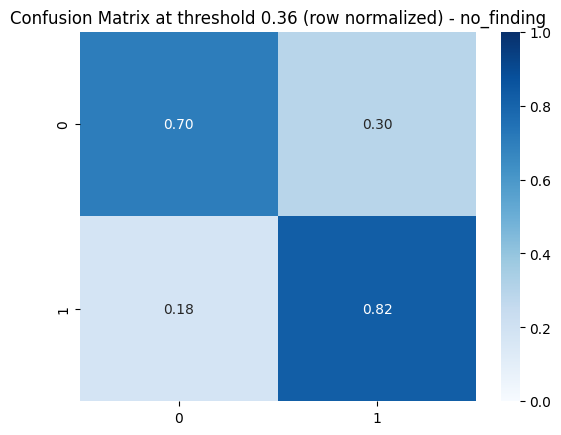

Confusion matrix without normalization - threshold 0.36450812220573425
[[824 347]
 [166 773]]

📈 Per-Class Metrics using threshold 0.36:
             Class  Precision    Recall        F1
0     pneumothorax   0.783019  0.786730  0.784870
1  support_devices   0.462882  0.785185  0.582418
2       no_finding   0.690179  0.823216  0.750850


In [254]:
# Create thresholded predictions using best thresholds per class
y_pred = np.zeros_like(y_probs)

for i, class_name in enumerate(class_names):
    threshold = best_thresholds[class_name]
    y_pred[:, i] = (y_probs[:, i] >= threshold).astype(int)

# New calculation using the final thresholds
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

# Use updated y_pred (from thresholded y_probs)
print("\n📊 Final Metrics after Applying Best Thresholds:")
best_threshold_metrics = {
    "accuracy": accuracy_score(y_true, y_pred),
    "macro_precision": precision_score(y_true, y_pred, average="macro"),
    "macro_recall": recall_score(y_true, y_pred, average="macro"),
    "macro_f1": f1_score(y_true, y_pred, average="macro"),
    "micro_precision": precision_score(y_true, y_pred, average="micro"),
    "micro_recall": recall_score(y_true, y_pred, average="micro"),
    "micro_f1": f1_score(y_true, y_pred, average="micro"),
    "weighted_precision": precision_score(y_true, y_pred, average="weighted"),
    "weighted_recall": recall_score(y_true, y_pred, average="weighted"),
    "weighted_f1": f1_score(y_true, y_pred, average="weighted"),
    "weighted_auc": roc_auc_score(y_true, y_probs, average="weighted"),
    
}
# wandb.log(metrics)
from pprint import pprint
pprint(best_threshold_metrics)

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=target_names, zero_division=0))
# Generate the classification report as a dictionary
report_dict_best_threshold = classification_report(y_true, y_pred, target_names=target_names, output_dict=True, zero_division=0)

# Convert to DataFrame
report_df_best_threshold = pd.DataFrame(report_dict_best_threshold).transpose()

per_class_metrics_threshold = []

for i, class_name in enumerate(class_names):
    threshold = best_thresholds[class_name]

    # Confusion Matrix optimized per threshold
    cm_threshold = confusion_matrix(y_true[:, i], y_pred[:, i], normalize='true')
    cm_raw_threshold = confusion_matrix(y_true[:, i], y_pred[:, i])
    fig_cm, ax = plt.subplots()
    sns.heatmap(cm_threshold, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax)
    ax.set_title(f"Confusion Matrix at threshold {threshold:.2f} (row normalized) - {class_name}")
    wandb.log({f"Confusion_{class_name}_threshold_{threshold}": wandb.Image(fig_cm)})
    plt.show()
    plt.close(fig_cm)
    print(f'Confusion matrix without normalization - threshold {threshold}')
    print(cm_raw_threshold)

    # Store per-class metrics
    per_class_metrics_threshold.append({
        "Class": class_name,
        # "AUC": roc_auc,
        # "Average Precision (AP)": ap,
        "Precision": precision_score(y_true[:, i], y_pred[:, i], zero_division=0),
        "Recall": recall_score(y_true[:, i], y_pred[:, i], zero_division=0),
        "F1": f1_score(y_true[:, i], y_pred[:, i], zero_division=0)
    })

# Optional: Display per-class metrics nicely
per_class_df_threshold = pd.DataFrame(per_class_metrics_threshold)
print(f"\n📈 Per-Class Metrics using threshold {threshold:.2f}:")
print(per_class_df_threshold)

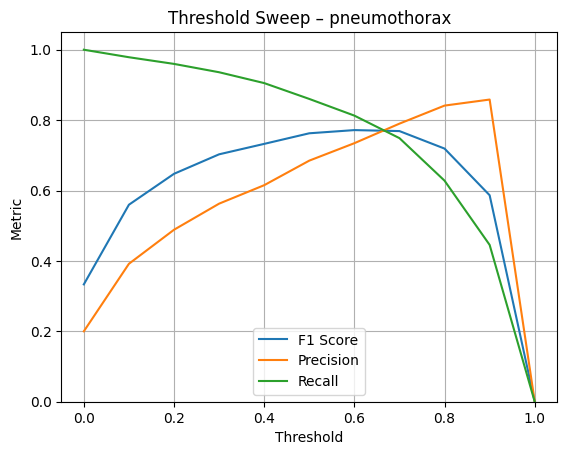

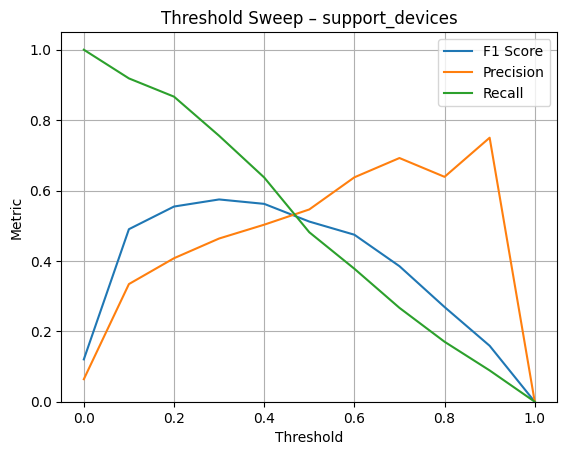

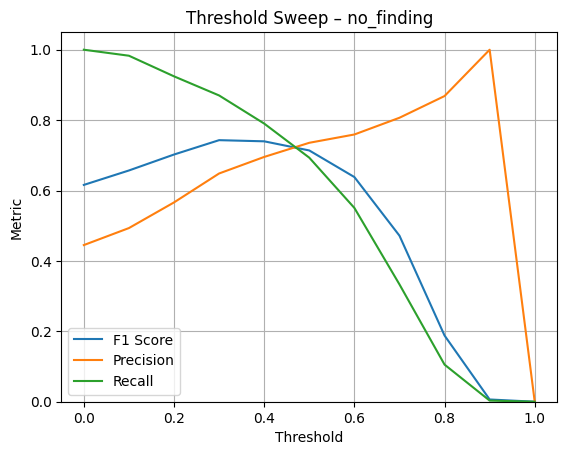

,Class,Threshold,Precision,Recall,F1 Score,TP,FP,FN,TN,total
0,pneumothorax,0.0,0.2000,1.0000,0.3333,422,1688,0,0,2110
1,pneumothorax,0.1,0.3918,0.9787,0.5596,413,641,9,1047,2110
2,pneumothorax,0.2,0.4885,0.9597,0.6475,405,424,17,1264,2110
3,pneumothorax,0.3,0.5627,0.9360,0.7028,395,307,27,1381,2110
4,pneumothorax,0.4,0.6151,0.9052,0.7325,382,239,40,1449,2110
5,pneumothorax,0.5,0.6849,0.8602,0.7626,363,167,59,1521,2110
6,pneumothorax,0.6,0.7345,0.8128,0.7717,343,124,79,1564,2110
7,pneumothorax,0.7,0.7900,0.7488,0.7689,316,84,106,1604,2110
8,pneumothorax,0.8,0.8413,0.6280,0.7191,265,50,157,1638,2110
9,pneumothorax,0.9,0.8584,0.4455,0.5866,188,31,234,1657,2110


In [255]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score, f1_score
import wandb

# Simulated input (replace with your own)
# y_true: shape (n_samples, n_classes)
# y_probs: predicted probabilities, same shape
# class_names: list of class names

thresholds = np.arange(0.0, 1.01, 0.1)
all_rows = []

# Loop through each class
for i, class_name in enumerate(class_names):
    true = y_true[:, i]
    probs = y_probs[:, i]

    # For overlay plot
    f1s, precisions, recalls = [], [], []

    for t in thresholds:
        preds = (probs >= t).astype(int)
        precision = precision_score(true, preds, zero_division=0)
        recall = recall_score(true, preds, zero_division=0)
        f1 = f1_score(true, preds, zero_division=0)
        tp = np.sum((true == 1) & (preds == 1))
        fp = np.sum((true == 0) & (preds == 1))
        fn = np.sum((true == 1) & (preds == 0))
        tn = int(np.sum((true == 0) & (preds == 0)))
        total_samples = tp + fp + fn + tn

        # Store metrics
        all_rows.append({
            "Class": class_name,
            "Threshold": round(t, 2),
            "Precision": round(precision, 4),
            "Recall": round(recall, 4),
            "F1 Score": round(f1, 4),
            "TP": int(tp),
            "FP": int(fp),
            "FN": int(fn),
            "TN": tn,
            "total": total_samples
        })

        f1s.append(f1)
        precisions.append(precision)
        recalls.append(recall)

    # Create overlay plot
    fig, ax = plt.subplots()
    ax.plot(thresholds, f1s, label="F1 Score")
    ax.plot(thresholds, precisions, label="Precision")
    ax.plot(thresholds, recalls, label="Recall")
    ax.set_title(f"Threshold Sweep – {class_name}")
    ax.set_xlabel("Threshold")
    ax.set_ylabel("Metric")
    ax.set_ylim(0, 1.05)
    ax.legend()
    ax.grid(True)
    wandb.log({f"Threshold Metrics - {class_name}": wandb.Image(fig)})
    plt.show()
    plt.close(fig)

# Log table to WandB
threshold_df = pd.DataFrame(all_rows)
table = wandb.Table(dataframe=threshold_df)
wandb.log({"Threshold Table (All Classes)": table})
threshold_df


In [256]:
i = 0
true = y_true[:, i]
probs = y_probs[:, i]

desired_precision = np.arange(0.4,0.85,0.05)
desired_recall = np.arange(0.75,1,0.05)

for desired_prec in desired_precision:
    best_recall = 0
    best_threshold = 0
    precision, recall, thresholds = precision_recall_curve(true, probs)
    for thr, prec, rec in zip(thresholds, precision, recall):
        if prec >= desired_prec:  # minimum acceptable precision
            if rec > best_recall:
                best_recall = rec
                best_threshold = thr

    print(f"✅ Best threshold = {best_threshold:.2f} with Recall = {best_recall:.3f} and Precision >= {desired_prec:.2f}")

for desired_recall in desired_recall:
    best_precision = 0
    best_threshold = 0
    precision, recall, thresholds = precision_recall_curve(true, probs)
    for thr, prec, rec in zip(thresholds, precision, recall):
        if rec >= desired_recall:  # minimum acceptable precision
            if prec > best_precision:
                best_precision = prec
                best_threshold = thr

    print(f"✅ Best threshold = {best_threshold:.2f} with Precision = {best_precision:.3f} and Recall >= {desired_recall:.2f}")


✅ Best threshold = 0.11 with Recall = 0.976 and Precision >= 0.40
✅ Best threshold = 0.16 with Recall = 0.969 and Precision >= 0.45
✅ Best threshold = 0.22 with Recall = 0.953 and Precision >= 0.50
✅ Best threshold = 0.28 with Recall = 0.943 and Precision >= 0.55
✅ Best threshold = 0.37 with Recall = 0.910 and Precision >= 0.60
✅ Best threshold = 0.44 with Recall = 0.886 and Precision >= 0.65
✅ Best threshold = 0.54 with Recall = 0.839 and Precision >= 0.70
✅ Best threshold = 0.62 with Recall = 0.803 and Precision >= 0.75
✅ Best threshold = 0.74 with Recall = 0.692 and Precision >= 0.80
✅ Best threshold = 0.70 with Precision = 0.791 and Recall >= 0.75
✅ Best threshold = 0.63 with Precision = 0.758 and Recall >= 0.80
✅ Best threshold = 0.52 with Precision = 0.692 and Recall >= 0.85
✅ Best threshold = 0.42 with Precision = 0.634 and Recall >= 0.90
✅ Best threshold = 0.23 with Precision = 0.509 and Recall >= 0.95
wandb: 🚀 View run NIH - PTX multilabel (+no_finding, support devices - EFFB5